In [1]:
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
from cartopy.util import add_cyclic_point
from pathlib import Path
import xcdat as xc
import cmasher as cmr
import xarray as xr
import sys

sys.path.append('../../functions/')
from lag_linregress import *
from monthly_departures import *
from MCA import *

# Reload edited Python modules automatically before running subsequent cells.
%load_ext autoreload
%autoreload 2

import sys

# Add the project folder only once, even if this cell is rerun.
functions_path = "/scratch/leiff/MCA/amip_clean/project_functions/"
if functions_path not in sys.path:
    sys.path.append(functions_path)

from MCA_cov import *
from significance import *
from plotting import *
from diagnostics import *
# from taylor_setup import *
from setup_diagnostic import *

In [2]:
# %% 1. Settings: AMIP running windows + observations + existing three-experiment HP
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from pathlib import Path

wc_core = Path("/scratch/leiff/MCA/amip_clean/data/maps_2000_2014_covImp/overlap_core_200003_201412")
wc_raw = Path("/scratch/leiff/MCA/amip_clean/data")
wc_running_dir = wc_core / "stationarity/four_region_attribution/run_01"
wc_hp_path = wc_core / "fullperiod_highpass/SEP_10yr_run01/regional_I_HP.npy"
wc_output_dir = wc_core / "stationarity/window_length_comparison/run_01"
wc_obs_paths = {"T": wc_raw / "ERA5/tas_194001-202412_g025.nc",
                "R": wc_raw / "CERES/CERES_net_200003-202604_g025.nc"}
wc_regions = ["WPWP", "SEP", "SEPn", "SEPs"]
wc_lengths = [178, 298, 598]                 # March to December: 15, 25 and 50 calendar-year spans.
wc_raw_start, wc_raw_end = "1870-03", "2014-12"
wc_obs_periods = {"2000_2014": ("2000-03", "2014-12"), "2000_2024": ("2000-03", "2024-12")}
wc_confirmed_member_ids = None              # Optional {model: raw member IDs in archived order}.
wc_preprocessing_tag = "same_monthly_detrend_as_stationarity_v1"
wc_resume, wc_io_block_months = True, 120
wc_central_fraction = .80                   # Model-balanced member spread, NOT an MMM CI.

# Run/import YOUR detrend_monthly_fast before calculation cells 3-6. It must
# accept time-first arrays and variable window lengths. No high-pass filter is
# applied to this running-window branch, and no new detrending method is supplied.
# Later plot only: cells 1-2, 8-9. Calculation checkpoints are independent of plots.
# Keep one writer per output directory. Changed scientific settings need a new dir.




In [3]:
# %% 2. Small helpers: dates, protected saves, raw input, index and spread calculations
def wc_months(first, last):
    return np.arange(np.datetime64(first, "M"), np.datetime64(last, "M") + np.timedelta64(1, "M"))


def wc_windows(months, length):
    """All complete March-start windows; label by START year, not midpoint."""
    start_indices = np.flatnonzero((months.astype(int) % 12 == 2) & (np.arange(len(months)) + length <= len(months)))
    if not len(start_indices):
        raise ValueError(f"No complete {length}-month windows in the supplied record.")
    starts, ends = months[start_indices], months[start_indices + length - 1]
    return {"start_year": starts.astype("datetime64[Y]").astype(int) + 1970,
            "start_month": starts, "end_month": ends, "start_index": start_indices, "n_months": int(length)}


def wc_fingerprint(settings):
    import hashlib
    import json
    def convert(value):
        if isinstance(value, np.ndarray):
            return value.astype(str).tolist() if value.dtype.kind in "Mm" else value.tolist()
        if isinstance(value, np.generic):
            return value.item()
        raise TypeError(type(value))
    return hashlib.sha256(json.dumps(settings, default=convert, sort_keys=True, allow_nan=False).encode()).hexdigest()


def wc_file_info(path):
    path = Path(path)
    return {"path": str(path), "size": path.stat().st_size, "mtime_ns": path.stat().st_mtime_ns}


def wc_save(path, payload, replace=False):
    """Publish only a complete file; interruption cannot leave a half-written .npy."""
    import os
    import tempfile
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = None
    try:
        with tempfile.NamedTemporaryFile(dir=path.parent, prefix=f".{path.name}.", suffix=".tmp", delete=False) as handle:
            temporary = Path(handle.name)
            np.save(handle, payload, allow_pickle=True)
            handle.flush()
            os.fsync(handle.fileno())
        if replace:
            os.replace(temporary, path)
        else:
            os.link(temporary, path)  # Refuses accidental replacement of an existing member.
    finally:
        if temporary is not None and temporary.exists():
            temporary.unlink()


def wc_checkpoint(path, signature, shapes, resume=True):
    """Reuse matching complete results; preserve corrupt files before recalculation."""
    import pickle
    from uuid import uuid4
    path = Path(path)
    if not path.exists():
        return None
    if not resume:
        raise FileExistsError(f"{path}: resume is disabled; select a new output directory.")
    try:
        saved = np.load(path, allow_pickle=True).item()
    except (ValueError, EOFError, OSError, pickle.UnpicklingError):
        saved = None
    if isinstance(saved, dict) and "signature" in saved and saved["signature"] != signature:
        raise ValueError(f"{path}: inputs/settings changed. Use a new output directory.")
    if isinstance(saved, dict) and saved.get("signature") == signature and isinstance(saved.get("values"), dict):
        if set(saved["values"]) == set(shapes) and all(np.shape(saved["values"][k]) == shape
                and np.isfinite(saved["values"][k]).all() for k, shape in shapes.items()):
            return saved
    backup = path.with_name(f"{path.name}.incomplete-{uuid4().hex[:8]}")
    path.rename(backup)
    print(f"Preserved incomplete output as {backup.name}", flush=True)
    return None


def wc_prepare_field(field, months, lat, lon):
    """Select/check monthly dates and grid; expose (member,time,lat,lon)."""
    allowed = {"K", "kelvin", "Kelvin"} if field.name in ["tas", "t2m"] else {"W m-2", "W m^-2", "W m**-2", "W/m2", "W/m^2", "W m−2"}
    if field.attrs.get("units") is not None and field.attrs["units"] not in allowed:
        raise ValueError(f"{field.name}: convert units {field.attrs['units']!r} explicitly.")
    field = field.sel(time=slice(str(months[0]), str(months[-1])))
    actual = np.asarray(field.time.dt.year*12 + field.time.dt.month - 1)
    if not np.array_equal(actual, months.astype(int) + 1970*12):
        raise ValueError(f"{field.name}: missing, repeated or reordered months.")
    for dim, expected in [("lat", lat), ("lon", lon)]:
        if field[dim].shape != expected.shape or not np.allclose(field[dim], expected, rtol=0, atol=1e-6):
            raise ValueError(f"{field.name}: {dim} differs from the saved grid/order.")
    extra = [d for d in field.dims if d not in ["time", "lat", "lon"]]
    if len(extra) > 1:
        raise ValueError(f"Select extra dimensions explicitly: {field.dims}")
    if extra:
        dim = extra[0]
        ids = np.asarray(field[dim]).astype(str) if dim in field.coords else np.arange(field.sizes[dim]).astype(str)
        field = field.rename({dim: "member"}) if dim != "member" else field
        field = field.assign_coords(member=ids)
    else:
        field = field.expand_dims(member=["single"])
    if len(set(field.member.values.tolist())) != field.sizes["member"]:
        raise ValueError("Repeated raw member labels.")
    return field.transpose("member", "time", "lat", "lon")


def wc_read_reduced(T_field, R_field, weights, source_mask, block_months=120):
    """For one member: raw T at source cells and raw GLOBAL R, time first.

    Fixed-weight spatial averaging commutes with the common linear monthly
    detrending. Reading R in blocks avoids keeping a full monthly global field.
    T is indexed by paired lat/lon positions, not their Cartesian product.
    """
    if block_months < 1:
        raise ValueError("block_months must be positive.")
    rows, cols = np.where(source_mask)
    T = T_field.isel(lat=xr.DataArray(rows, dims="cell"), lon=xr.DataArray(cols, dims="cell"))
    T = np.asarray(T.transpose("time", "cell").values, dtype=float)
    Rg = np.empty(R_field.sizes["time"])
    support = weights > 0
    for first in range(0, len(Rg), block_months):
        last = min(first + block_months, len(Rg))
        block = np.asarray(R_field.isel(time=slice(first, last)).values, dtype=float)
        if not np.isfinite(block[:, support]).all():
            raise ValueError("Missing radiation on the fixed GLOBAL support; no changing monthly masks.")
        Rg[first:last] = np.sum(block[:, support]*weights[support], axis=1)
    if len(T) != len(Rg) or not np.isfinite(T).all():
        raise ValueError("Missing regional T or mismatched T/R lengths.")
    return T, Rg


def wc_one_window(T_raw, Rg_raw, source_weights, preprocess):
    """I for every source region from the SAME window-specific processed data."""
    # detrend_monthly_fast removes monthly climatology AND monthwise trends.
    # Copies protect raw data when a user's function modifies inputs in place.
    T, Rg = [np.asarray(preprocess(v.copy()), dtype=float) for v in [T_raw, Rg_raw]]
    if T.shape != T_raw.shape or Rg.shape != Rg_raw.shape or not np.isfinite(T).all() or not np.isfinite(Rg).all():
        raise ValueError("detrend_monthly_fast must preserve shapes and return finite arrays.")
    T, Rg = T - T.mean(axis=0), Rg - Rg.mean()
    sigma_T = T.std(axis=0, ddof=1)
    if np.any(sigma_T <= 0):
        raise ValueError("A requested source cell has zero T SD; its Zi is undefined.")
    Z = T / sigma_T
    cov_Zi_R = np.sum(Z*Rg[:, None], axis=0)/(len(Rg) - 1)
    values = {r: float(np.sum(p*cov_Zi_R)) for r, p in source_weights.items()}
    # Independent covariance-of-the-regional-index check; A is NOT restandardized.
    for region, p in source_weights.items():
        A = np.sum(Z*p, axis=1)
        np.testing.assert_allclose(values[region], np.cov(A, Rg, ddof=1)[0, 1], rtol=1e-8, atol=1e-10)
    return values


def wc_member_spread(member_values, central_fraction=.8):
    """Equal-model MMM and central member percentiles, independently per window."""
    if not 0 < central_fraction < 1:
        raise ValueError("central_fraction must lie between zero and one.")
    arrays = [np.asarray(v, dtype=float) for v in member_values.values()]
    if not arrays or any(a.ndim != 2 or not len(a) or a.shape[1] != arrays[0].shape[1]
                         or not np.isfinite(a).all() for a in arrays):
        raise ValueError("Expected complete (member,window) arrays for a fixed model population.")
    values = np.concatenate(arrays)
    probabilities = np.concatenate([np.full(len(a), 1/(len(arrays)*len(a))) for a in arrays])
    model_means = np.stack([a.mean(axis=0) for a in arrays])
    quantiles = np.array([(1-central_fraction)/2, (1+central_fraction)/2])
    bounds = np.empty((2, values.shape[1]))
    for s in range(values.shape[1]):
        order = np.argsort(values[:, s])
        cumulative = np.cumsum(probabilities[order])
        cumulative /= cumulative[-1]
        positions = np.searchsorted(cumulative, quantiles-8*np.finfo(float).eps)
        bounds[:, s] = values[order[np.minimum(positions, len(order)-1)], s]
    return {"MMM": model_means.mean(axis=0), "lower": bounds[0], "upper": bounds[1],
            "minimum": values.min(axis=0), "maximum": values.max(axis=0),
            "n_models": len(arrays), "n_members": len(values), "central_fraction": central_fraction}




In [4]:
# %% 3. Reuse the 178-month series; register the new windows and exact source masks
if not callable(globals().get("detrend_monthly_fast")):
    raise NameError("Import/paste your detrend_monthly_fast before running calculations.")
wc_catalog = np.load(wc_running_dir / "catalog.npy", allow_pickle=True).item()
wc_original = np.load(wc_running_dir / wc_catalog["series_file"], allow_pickle=True).item()
wc_hp = np.load(wc_hp_path, allow_pickle=True).item()
if wc_original["signature"] != wc_catalog["signature"]:
    raise ValueError("Running catalog and series come from different calculations.")
wc_lat, wc_lon = [np.asarray(wc_catalog["coordinates"][d]) for d in ["lat", "lon"]]
wc_weights = np.asarray(wc_catalog["weights"], dtype=float)
if wc_weights.shape != (len(wc_lat), len(wc_lon)) or not np.isfinite(wc_weights).all() or np.any(wc_weights < 0) or wc_weights.sum() <= 0:
    raise ValueError("Invalid global area weights.")
wc_weights = wc_weights / wc_weights.sum()
wc_masks = {}
for region in wc_regions:
    mask = np.asarray(wc_catalog["regions"][region], dtype=float)
    if mask.shape != wc_weights.shape:
        raise ValueError(f"{region}: mask shape differs from the grid.")
    wc_masks[region] = np.isfinite(mask) & (mask != 0) & (wc_weights > 0)
    if not wc_masks[region].any():
        raise ValueError(f"{region}: empty mask.")
wc_union = np.logical_or.reduce(list(wc_masks.values()))
wc_source_weights = {r: np.where(m[wc_union], wc_weights[wc_union], 0.) for r, m in wc_masks.items()}
wc_source_weights = {r: p / p.sum() for r, p in wc_source_weights.items()}
wc_month_axis = wc_months(wc_raw_start, wc_raw_end)
if wc_lengths != [178, 298, 598]:
    raise ValueError("This comparison uses March-to-December 178, 298 and 598-month windows.")
wc_window_coordinates = {n: wc_windows(wc_month_axis, n) for n in wc_lengths}
wc_models = list(wc_catalog["model_names"]["amip_hist"])
wc_labels = wc_catalog["member_labels"]["amip_hist"]
if not wc_models or len(set(wc_models)) != len(wc_models):
    raise ValueError("Expected a nonempty, unique AMIP model population.")
if wc_models != list(wc_original["model_names"]["amip_hist"]):
    raise ValueError("Running catalog and series model order differs.")
for dim in ["start_year", "start_month", "end_month"]:
    np.testing.assert_array_equal(wc_window_coordinates[178][dim], wc_original["coordinates"][dim])

# Require the same grid/regions, and the same AMIP member identities for the HP
# comparison. Historical-only models remain in the historical-all violin.
for dim, value in [("lat", wc_lat), ("lon", wc_lon)]:
    np.testing.assert_array_equal(wc_hp["coordinates"][dim], value)
np.testing.assert_allclose(wc_hp["weights"], wc_weights, rtol=1e-10, atol=1e-14)
if set(wc_hp["model_names"]["amip_hist"]) != set(wc_models):
    raise ValueError("HP and running AMIP model populations differ; align them explicitly.")
for r in wc_regions:
    np.testing.assert_array_equal(wc_hp["regions"][r], wc_masks[r])
for model in wc_models:
    np.testing.assert_array_equal(wc_labels[model], wc_original["member_labels"]["amip_hist"][model])
    np.testing.assert_array_equal(wc_labels[model], wc_hp["member_labels"]["amip_hist"][model])

# One outer key per window length; inside, retain region -> experiment -> quantity
# -> model. The existing 178-month arrays are copied, never recalculated/overwritten.
wc_member_values = {n: {r: {"amip_hist": {"I": {}}} for r in wc_regions} for n in wc_lengths}
for region in wc_regions:
    for model in wc_models:
        v = np.asarray(wc_original["member_values"][region]["amip_hist"]["I"][model], dtype=float)
        if v.shape != (len(wc_labels[model]), len(wc_window_coordinates[178]["start_year"])) or not np.isfinite(v).all():
            raise ValueError(f"{region}/{model}: incomplete 178-month reference series.")
        wc_member_values[178][region]["amip_hist"]["I"][model] = v.copy()

import inspect
try:
    wc_detrend_source = inspect.getsource(detrend_monthly_fast)
except (OSError, TypeError):
    wc_detrend_source = "Source unavailable; the preprocessing tag must identify the unchanged function."
wc_settings = {"schema": "regional_window_comparison_v1", "running_signature": wc_catalog["signature"],
               "running_series_source": wc_file_info(wc_running_dir / wc_catalog["series_file"]),
               "regions": wc_masks, "weights": wc_weights, "months": wc_month_axis, "lengths": wc_lengths,
               "lat": wc_lat, "lon": wc_lon, "models": wc_models, "member_labels": wc_labels,
               "preprocessing_tag": wc_preprocessing_tag, "preprocessing_source": wc_detrend_source,
               "ddof": 1, "observation_periods": wc_obs_periods}
wc_signature = wc_fingerprint(wc_settings)
wc_settings_path = wc_output_dir / "settings.npy"
if wc_settings_path.exists():
    if np.load(wc_settings_path, allow_pickle=True).item()["signature"] != wc_signature:
        raise ValueError("Output settings changed. Choose a new wc_output_dir.")
else:
    wc_save(wc_settings_path, {"signature": wc_signature, "settings": wc_settings})
for n, c in wc_window_coordinates.items():
    print(f"{n} months: March starts {c['start_year'][0]}–{c['start_year'][-1]}; last window ends {c['end_month'][-1]}")




178 months: March starts 1870–2000; last window ends 2014-12
298 months: March starts 1870–1990; last window ends 2014-12
598 months: March starts 1870–1965; last window ends 2014-12


In [5]:
# %% 4. Observational reference lines: process EACH requested period independently
# The long observed record and longer model windows both use 298 months.
# Recompute the short record too and compare it with the existing observed map.
# The saved original map is never changed. Only four scalar indices per period
# are needed here; raw T/R maps are not retained in this derived archive.
wc_overlap_obs_path = wc_core / "overlap_observations.npy"
wc_obs_sources = {k: wc_file_info(p) for k, p in wc_obs_paths.items()}
wc_obs_sources["original_overlap"] = wc_file_info(wc_overlap_obs_path)
wc_obs_signature = wc_fingerprint({"run": wc_signature, "sources": wc_obs_sources})
wc_obs_keys = {f"{period}/{r}": () for period in wc_obs_periods for r in wc_regions}
wc_obs_saved = wc_checkpoint(wc_output_dir / "observations.npy", wc_obs_signature, wc_obs_keys, wc_resume)
wc_observation_coordinates = {p: {"start_month": first, "end_month": last, "n_months": len(wc_months(first, last))}
                              for p, (first, last) in wc_obs_periods.items()}
if wc_obs_saved is None:
    obs_months = wc_months("2000-03", "2024-12")
    with xr.open_dataset(wc_obs_paths["T"]) as ds_T, xr.open_dataset(wc_obs_paths["R"]) as ds_R:
        T = wc_prepare_field(ds_T["t2m"], obs_months, wc_lat, wc_lon)
        R = wc_prepare_field(ds_R["toa_net_all_mon"], obs_months, wc_lat, wc_lon)
        if T.sizes["member"] != 1 or R.sizes["member"] != 1:
            raise ValueError("Expected single ERA5 and CERES fields, not ensembles.")
        obs_T, obs_Rg = wc_read_reduced(T.isel(member=0), R.isel(member=0), wc_weights, wc_union, wc_io_block_months)
    wc_obs_values = {}
    for period, (first, last) in wc_obs_periods.items():
        selected = (obs_months >= np.datetime64(first, "M")) & (obs_months <= np.datetime64(last, "M"))
        v = wc_one_window(obs_T[selected], obs_Rg[selected], wc_source_weights, detrend_monthly_fast)
        wc_obs_values.update({f"{period}/{r}": value for r, value in v.items()})
    old_obs = np.load(wc_overlap_obs_path, allow_pickle=True).item()
    if "cov_Zi_R" in old_obs:
        old_map = np.asarray(old_obs["cov_Zi_R"], dtype=float)
    else:
        old_map = np.asarray(old_obs["corr_Ti_R"], dtype=float) * old_obs["sigma_R"]
    if old_map.shape != wc_weights.shape or not np.isfinite(old_map[wc_union]).all():
        raise ValueError("Existing observed covariance map is missing on the requested regions.")
    for region, p in wc_source_weights.items():
        np.testing.assert_allclose(wc_obs_values[f"2000_2014/{region}"], np.sum(p*old_map[wc_union]), rtol=1e-7, atol=1e-9,
                                   err_msg=f"{region}: short observations differ; check preprocessing and weights")
    wc_obs_saved = {"values": wc_obs_values, "signature": wc_obs_signature, "sources": wc_obs_sources,
                    "coordinates": wc_observation_coordinates}
    wc_save(wc_output_dir / "observations.npy", wc_obs_saved)
    del obs_T, obs_Rg
wc_observations = {p: {r: {"I": wc_obs_saved["values"][f"{p}/{r}"]} for r in wc_regions} for p in wc_obs_periods}
print("Observed regional indices:", wc_observations)




Observed regional indices: {'2000_2014': {'WPWP': {'I': -0.17775891700769775}, 'SEP': {'I': 0.1220055267819847}, 'SEPn': {'I': 0.15315752809242122}, 'SEPs': {'I': 0.09093841813620925}}, '2000_2024': {'WPWP': {'I': -0.1634927405302465}, 'SEP': {'I': 0.10395882580394102}, 'SEPn': {'I': 0.09907945878180781}, 'SEPs': {'I': 0.10882489600882517}}}


In [6]:
# %% 5. New 298-/598-month member indices, with per-length/member restart checks
# Only source-region T and global R are needed, reducing memory and calculation.
# Each member is read once if anything is missing. Complete member/length files
# are skipped. A dropped job repeats only an unfinished member/length calculation.
wc_member_files, wc_raw_sources = {}, {}
for model in wc_models:
    print(f"AMIP / {model}", flush=True)
    paths = {}
    for variable in ["tas", "N"]:
        found = sorted((wc_raw / "AMIP" / model).glob(f"{variable}_Amon_{model}_*amip-hist*combined*187001-201412_g025.nc"))
        if len(found) != 1:
            raise ValueError(f"{model}/{variable}: expected one combined file; found {found}")
        paths[variable] = found[0]
    sources = {k: wc_file_info(p) for k, p in paths.items()}
    wc_raw_sources[model], wc_member_files[model] = sources, []
    labels = np.asarray(wc_labels[model])
    collected = {n: {r: [] for r in wc_regions} for n in [298, 598]}
    with xr.open_dataset(paths["tas"]) as ds_T, xr.open_dataset(paths["N"]) as ds_R:
        fields = {"T": wc_prepare_field(ds_T["tas"], wc_month_axis, wc_lat, wc_lon),
                  "R": wc_prepare_field(ds_R["N"], wc_month_axis, wc_lat, wc_lon)}
        if wc_confirmed_member_ids is not None:
            ids = np.asarray(wc_confirmed_member_ids[model]).astype(str)
            if ids.shape != labels.shape or len(set(ids.tolist())) != len(ids):
                raise ValueError("Confirmed IDs must have the archived member count and order.")
            fields = {k: f.sel(member=ids) for k, f in fields.items()}
        if any(f.sizes["member"] != len(labels) for f in fields.values()) or not np.array_equal(fields["T"].member, fields["R"].member):
            raise ValueError(f"{model}: raw member labels/count/order differ; provide confirmed IDs.")
        for member, label in enumerate(labels):
            raw_id = str(fields["T"].member.values[member])
            signatures, files, saved = {}, {}, {}
            for n in [298, 598]:
                signatures[n] = wc_fingerprint({"run": wc_signature, "sources": sources, "model": model,
                                                "member_label": label, "raw_member_id": raw_id, "n_months": n})
                files[n] = wc_output_dir / "members" / model / f"member_{member:03d}_n{n}.npy"
                shapes = {r: (len(wc_window_coordinates[n]["start_year"]),) for r in wc_regions}
                saved[n] = wc_checkpoint(files[n], signatures[n], shapes, wc_resume)
            missing = [n for n in [298, 598] if saved[n] is None]
            if missing:
                raw_T, raw_Rg = wc_read_reduced(fields["T"].isel(member=member), fields["R"].isel(member=member),
                                              wc_weights, wc_union, wc_io_block_months)
                # Check first/middle/last OLD windows against this exact member.
                # This tests both member alignment and the linear spatial-average
                # shortcut before spending time on the longer calculations.
                old = wc_window_coordinates[178]
                for s in sorted({0, len(old["start_index"])//2, len(old["start_index"])-1}):
                    first = old["start_index"][s]
                    check = wc_one_window(raw_T[first:first+178], raw_Rg[first:first+178], wc_source_weights, detrend_monthly_fast)
                    for region, value in check.items():
                        reference = wc_member_values[178][region]["amip_hist"]["I"][model][member, s]
                        np.testing.assert_allclose(value, reference, rtol=1e-7, atol=1e-9,
                            err_msg=f"{model}/{label}/{region}: original 178-month index differs")
                for n in missing:
                    coords = wc_window_coordinates[n]
                    values = {r: np.empty(len(coords["start_index"])) for r in wc_regions}
                    for s, first in enumerate(coords["start_index"]):
                        v = wc_one_window(raw_T[first:first+n], raw_Rg[first:first+n], wc_source_weights, detrend_monthly_fast)
                        for region in wc_regions:
                            values[region][s] = v[region]
                    saved[n] = {"values": values, "signature": signatures[n], "member_label": label,
                                "raw_member_id": raw_id, "sources": sources, "coordinates": coords}
                    wc_save(files[n], saved[n])
                    print(f"  member {member+1}/{len(labels)}: saved {n}-month windows", flush=True)
                del raw_T, raw_Rg
            else:
                print(f"  member {member+1}/{len(labels)}: reused both lengths", flush=True)
            for n in [298, 598]:
                for region in wc_regions:
                    collected[n][region].append(saved[n]["values"][region])
            wc_member_files[model].append({n: str(p.relative_to(wc_output_dir)) for n, p in files.items()})
    for n in [298, 598]:
        for region in wc_regions:
            wc_member_values[n][region]["amip_hist"]["I"][model] = np.stack(collected[n][region])




AMIP / BCC-CSM2-MR
  member 1/1: saved 298-month windows
  member 1/1: saved 598-month windows
AMIP / CAMS-CSM1-0
  member 1/3: saved 298-month windows
  member 1/3: saved 598-month windows
  member 2/3: saved 298-month windows
  member 2/3: saved 598-month windows
  member 3/3: saved 298-month windows
  member 3/3: saved 598-month windows
AMIP / CESM2
  member 1/3: saved 298-month windows
  member 1/3: saved 598-month windows
  member 2/3: saved 298-month windows
  member 2/3: saved 598-month windows
  member 3/3: saved 298-month windows
  member 3/3: saved 598-month windows
AMIP / CIESM
  member 1/3: saved 298-month windows
  member 1/3: saved 598-month windows
  member 2/3: saved 298-month windows
  member 2/3: saved 598-month windows
  member 3/3: saved 298-month windows
  member 3/3: saved 598-month windows
AMIP / CNRM-CM6-1-HR
  member 1/1: saved 298-month windows
  member 1/1: saved 598-month windows
AMIP / CNRM-CM6-1
  member 1/10: saved 298-month windows
  member 1/10: saved 5

In [7]:
# %% 6. Member -> model -> MMM; descriptive member spreads; small final archive
wc_model_mean_values, wc_MMM_values, wc_spread = {}, {}, {}
fractions = {r: wc_weights[wc_masks[r]].sum()/wc_weights[wc_masks["SEP"]].sum() for r in ["SEPn", "SEPs"]}
for n in wc_lengths:
    wc_model_mean_values[n], wc_MMM_values[n], wc_spread[n] = {}, {}, {}
    for region in wc_regions:
        members = wc_member_values[n][region]["amip_hist"]["I"]
        means = {m: v.mean(axis=0) for m, v in members.items()}
        wc_model_mean_values[n][region] = {"amip_hist": {"I": means}}
        wc_spread[n][region] = wc_member_spread(members, wc_central_fraction)
        wc_MMM_values[n][region] = {"amip_hist": {"I": wc_spread[n][region]["MMM"]}}
        if n == 178:
            np.testing.assert_allclose(wc_spread[n][region]["MMM"], wc_original["MMM_values"][region]["amip_hist"]["I"],
                                       rtol=1e-8, atol=1e-10, err_msg=f"{region}: original MMM differs")
    for model in wc_models:
        get = lambda r: wc_member_values[n][r]["amip_hist"]["I"][model]
        np.testing.assert_allclose(get("SEP"), fractions["SEPn"]*get("SEPn") + fractions["SEPs"]*get("SEPs"),
                                   rtol=1e-8, atol=1e-10)
wc_archive = {"member_values": wc_member_values, "model_mean_values": wc_model_mean_values, "MMM_values": wc_MMM_values,
              "spread": wc_spread, "observations": wc_observations, "observation_coordinates": wc_observation_coordinates,
              "window_coordinates": wc_window_coordinates, "model_names": {"amip_hist": wc_models},
              "member_labels": {"amip_hist": wc_labels}, "coordinates": {"lat": wc_lat, "lon": wc_lon},
              "regions": wc_masks, "weights": wc_weights, "SEP_area_fractions": fractions,
              "HP": wc_hp, "signature": wc_signature, "settings": wc_settings,
              "sources": {"models": wc_raw_sources, "observations": wc_obs_sources, "HP": wc_file_info(wc_hp_path)},
              "member_files": wc_member_files,
              "metadata": {"units": "W m-2", "experiment": "amip_hist",
                 "index": "Regional mean Cov(Zi,Rg); local SD recomputed in each window; A not restandardized",
                 "aggregation": "Arithmetic member diagnostics -> model means -> equal-model MMM",
                 "spread": "Central model-balanced empirical member spread, not CI; fixed complete model population",
                 "interpretation": "Longer windows reestimate detrending and standardization; not just smoothing 178-month I",
                 "HP_context": "Separate full-retained-period high-pass preprocessing; not a duration-matched observational test"}}
wc_save(wc_output_dir / "window_comparison.npy", wc_archive, replace=(wc_output_dir / "window_comparison.npy").exists())
print(f"Saved {wc_output_dir / 'window_comparison.npy'}")




Saved /scratch/leiff/MCA/amip_clean/data/maps_2000_2014_covImp/overlap_core_200003_201412/stationarity/window_length_comparison/run_01/window_comparison.npy


In [8]:
# %% 7. Examples: access diagnostics without plotting or loading any monthly data
# Length -> region -> experiment -> quantity -> model, in the original member order.
# wc_member_values[298]["SEPn"]["amip_hist"]["I"]["TaiESM1"]       # (member,start_year)
# wc_model_mean_values[598]["WPWP"]["amip_hist"]["I"]["TaiESM1"]   # (start_year,)
# wc_MMM_values[178]["SEP"]["amip_hist"]["I"]                     # (start_year,)
# wc_observations["2000_2024"]["SEP"]["I"]                        # scalar, 298 months
# wc_window_coordinates[298]["start_year"]                        # 1870..1990




In [21]:
# %% 8. Plot function: four rows, running indices left and HP context right
def plot_regional_window_comparison(archive, *, figsize=(16, 13), ribbon_alpha=.12,
                                    show_full_range=False, show_hp_model_means=True,
                                    bw_adjust=1., row_ylims=None, year_position="start", savepath=None,
                                    lengths=[178, 298, 598]):
    """Same y scale within each row; label windows by start or end year.

    Left: AMIP equal-model MMMs and model-balanced central member spreads.
    Right: three-experiment HP member densities with equal model weight, model
    mean dots and equal-model MMM diamonds, as in the preceding violin notebook.
    """
    if not np.isfinite(bw_adjust) or bw_adjust <= 0:
        raise ValueError("bw_adjust must be positive.")
    if year_position not in ["start", "end"]:
        raise ValueError("year_position must be 'start' or 'end'.")
    regions = ["WPWP", "SEP", "SEPn", "SEPs"]
    # Read each window's actual stored dates rather than adding an approximate
    # number of years. Only horizontal placement changes: no statistics, ribbons
    # or HP/observational values are recalculated or shifted between windows.
    plot_years = {}
    for n in lengths:
        coords = archive["window_coordinates"][n]
        if year_position == "end":
            dates = np.asarray(coords["end_month"], dtype="datetime64[M]")
            if np.isnat(dates).any():
                raise ValueError(f"{n}: missing window-end dates.")
            years = dates.astype("datetime64[Y]").astype(int) + 1970
        else:
            years = np.asarray(coords["start_year"])
        if years.ndim != 1 or not len(years) or not np.isfinite(years).all() or np.any(np.diff(years) <= 0):
            raise ValueError(f"{n}: expected finite, increasing window years.")
        plot_years[n] = years
    xlimits = (min(y[0] for y in plot_years.values()), max(y[-1] for y in plot_years.values()))
    line_colors = {178: "#348CA4", 298: "#C47D32", 598: "#7960A6"}
    experiments = ["historical", "historical_matched", "amip_hist"]
    hp_colors = ["#707D91", "#D99045", "#348CA4"]
    periods, obs_styles = ["2000_2014", "2000_2024"], ["--", ":"]
    hp = archive["HP"]
    fig, axes = plt.subplots(4, 2, figsize=figsize, sharey="row", gridspec_kw={"width_ratios": [4.2, 1.5]}, layout="constrained")
    plotted = {}
    rng = np.random.default_rng(42)
    all_names = sorted({m for e in experiments for m in hp["model_names"][e]})
    jitter = dict(zip(all_names, rng.uniform(-.095, .095, len(all_names))))
    for row, region in enumerate(regions):
        left, right = axes[row]
        plotted[region] = {"running": {}, "HP": {}}
        for n in lengths:
            years = plot_years[n]
            spread = archive["spread"][n][region]
            if len(years) != len(spread["MMM"]):
                raise ValueError(f"{n}/{region}: mismatched window years and MMM.")
            color = line_colors[n]
            if show_full_range:
                left.fill_between(years, spread["minimum"], spread["maximum"], color=color, alpha=ribbon_alpha, lw=0)
            else:
                left.fill_between(years, spread["lower"], spread["upper"], color=color, alpha=ribbon_alpha, lw=0)
                # left.plot(years, spread["lower"], color=color, lw=.65, ls=":", alpha=.65)
                # left.plot(years, spread["upper"], color=color, lw=.65, ls=":", alpha=.65)
            left.plot(years, spread["MMM"], color=color, lw=2., zorder=4, label=f"{n} months")
            plotted[region]["running"][n] = {"years": years, **spread}

        # Same weighted Gaussian-density display as the HP violin notebook.
        # One shared smoothing bandwidth within a region; density stops at each
        # group's observed extrema. Duplicating a model's members changes no mass.
        samples = []
        for experiment in experiments:
            d = hp["member_values"][region][experiment]["I_HP"]
            arrays = [np.asarray(d[m], dtype=float) for m in hp["model_names"][experiment]]
            if not arrays or any(v.ndim != 1 or not len(v) or not np.isfinite(v).all() for v in arrays):
                raise ValueError(f"{region}/{experiment}: HP member indices must be complete.")
            v = np.concatenate(arrays)
            p = np.concatenate([np.full(len(a), 1/(len(arrays)*len(a))) for a in arrays])
            samples.append((v, p, np.array([a.mean() for a in arrays])))
        mixture, weights = np.concatenate([s[0] for s in samples]), np.concatenate([s[1]/3 for s in samples])
        center = np.sum(mixture*weights)
        bandwidth = .35*np.sqrt(np.sum(weights*(mixture-center)**2))*bw_adjust
        for position, (experiment, color, (values, p, means)) in enumerate(zip(experiments, hp_colors, samples)):
            y = np.linspace(values.min(), values.max(), 256)
            if np.ptp(values) > 0:
                density = np.exp(-.5*((y[:, None]-values)/bandwidth)**2) @ p
                width = .32*density/density.max()
                right.fill_betweenx(y, position-width, position+width, facecolor=color, edgecolor=color, alpha=.55, lw=.9)
            else:
                right.plot([position-.3, position+.3], [values[0]]*2, color=color, lw=3)
            MMM = hp["MMM_values"][region][experiment]["I_HP"]
            np.testing.assert_allclose(MMM, means.mean(), rtol=1e-10, atol=1e-12)
            if show_hp_model_means:
                right.scatter([position+jitter[m] for m in hp["model_names"][experiment]], means,
                              s=13, color=".2", edgecolor="white", lw=.35, alpha=.65, zorder=3)
            right.scatter(position, MMM, marker="D", s=45, color="black", edgecolor="white", lw=.7, zorder=4)
            plotted[region]["HP"][experiment] = {"values": values, "probabilities": p, "MMM": MMM}

        # Identical black observational reference levels on both axes. Their
        # preprocessing is the running-window method, NOT HP-filtered observations.
        for period, style in zip(periods, obs_styles):
            value = archive["observations"][period][region]["I"]
            for ax in [left, right]:
                ax.axhline(value, color="black", linestyle=style, lw=1.35, zorder=5)
                ax.axhline(0., color="k", lw=0.6, zorder=1,alpha=1)
        left.set_title(region, loc="left", fontsize=14, fontweight="bold")
        left.set_ylabel(r"Regional $I$ [W m$^{-2}$]")
        left.set_xlim(xlimits)
        right.set(xticks=[0, 1, 2], xticklabels=["Hist.\nall", "Hist.\nmatched", "AMIP"], xlim=(-.6, 2.6))
        for ax in [left, right]:
            ax.axhline(0., color=".65", lw=.6, zorder=0)
            ax.grid(axis="y", color=".92", lw=.6)
            ax.set_axisbelow(True)
            ax.spines[["top", "right"]].set_visible(False)
        if row_ylims is not None and region in row_ylims:
            left.set_ylim(row_ylims[region])
        if row < 3:
            left.tick_params(labelbottom=False)
            right.tick_params(labelbottom=False)
    axes[-1, 0].set_xlabel("Window start year (March)" if year_position == "start" else "Window end year (December)")
    axes[-1, 1].set_xlabel("Full-period HP experiment")
    line_handles = [Line2D([], [], color=line_colors[n], lw=2, label=f"{n} months" + ({298: " (25-year span)", 598: " (50-year span)"}.get(n, ""))) for n in lengths]
    for period, style in zip(periods, obs_styles):
        c = archive["observation_coordinates"][period]
        line_handles.append(Line2D([], [], color="black", ls=style, lw=1.4,
                            label=f"Obs {c['start_month']}–{c['end_month']} ({c['n_months']} mo)"))
    axes[0, 0].legend(handles=line_handles, loc="lower left", bbox_to_anchor=(0, 1.18), ncol=3, fontsize=11, frameon=False)
    hp_time = np.asarray(hp["coordinates"]["time"])
    axes[0, 1].set_title(f"High-pass context\n{str(hp_time[0])[:7]}–{str(hp_time[-1])[:7]}", fontsize=14, pad=12)
    hp_handles = [Line2D([], [], marker="o", ls="none", color=".2", markersize=4, label="Model mean"),
                  Line2D([], [], marker="D", ls="none", color="black", markersize=5, label="MMM")]
    if not show_hp_model_means:
        hp_handles = hp_handles[1:]
    axes[0, 1].legend(handles=hp_handles, loc="lower center", bbox_to_anchor=(.5, 1.27), ncol=2, frameon=False, fontsize=9)
    
        
    fraction = archive["spread"][178]["SEP"]["central_fraction"]
    fig.suptitle("AMIP-hist regional covariance across window lengths", fontsize=16)
    if show_full_range:
        fig.supxlabel(f"Shading: complete ensemble member spread."
                   "All windows start in March and end in December; observations span 178 and 298 months.", fontsize=12)
    else:
        fig.supxlabel(f"Shading: model-balanced central {fraction:.0%} member spread (not CI). HP uses a separate preprocessing/period.\n"
                   "All windows start in March and end in December; observations span 178 and 298 months.", fontsize=12)
    if savepath is not None:
        path = Path(savepath)
        path.parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(path, dpi=250, bbox_inches="tight")
    return fig, axes, plotted




In [17]:
# %% 8. Plot function: four rows, running indices left and HP context right
def plot_regional_window_comparison(archive, *, figsize=(16, 13), ribbon_alpha=.12,
                                    show_full_range=False, show_hp_model_means=True,
                                    bw_adjust=1., row_ylims=None, year_position="start", savepath=None,
                                    lengths=[178, 298, 598], font_scale=1.):
    """Same y scale within each row; label windows by start or end year.

    Left: AMIP equal-model MMMs and model-balanced central member spreads.
    Right: three-experiment HP member densities with equal model weight, model
    mean dots and equal-model MMM diamonds, as in the preceding violin notebook.
    """
    if not np.isfinite(font_scale) or font_scale <= 0:
        raise ValueError("font_scale must be positive.")
    if not np.isfinite(bw_adjust) or bw_adjust <= 0:
        raise ValueError("bw_adjust must be positive.")
    if year_position not in ["start", "end"]:
        raise ValueError("year_position must be 'start' or 'end'.")
    regions = ["SEP","WPWP", "SEPn", "SEPs"]
    # Read each window's actual stored dates rather than adding an approximate
    # number of years. Only horizontal placement changes: no statistics, ribbons
    # or HP/observational values are recalculated or shifted between windows.
    plot_years = {}
    for n in lengths:
        coords = archive["window_coordinates"][n]
        if year_position == "end":
            dates = np.asarray(coords["end_month"], dtype="datetime64[M]")
            if np.isnat(dates).any():
                raise ValueError(f"{n}: missing window-end dates.")
            years = dates.astype("datetime64[Y]").astype(int) + 1970
        else:
            years = np.asarray(coords["start_year"])
        if years.ndim != 1 or not len(years) or not np.isfinite(years).all() or np.any(np.diff(years) <= 0):
            raise ValueError(f"{n}: expected finite, increasing window years.")
        plot_years[n] = years
    xlimits = (min(y[0] for y in plot_years.values()), max(y[-1] for y in plot_years.values()))
    line_colors = {178: "#348CA4", 298: "#C47D32", 598: "#7960A6"}
    experiments = ["historical", "historical_matched", "amip_hist"]
    hp_colors = ["#707D91", "#D99045", "#348CA4"]
    periods, obs_styles = ["2000_2014", "2000_2024"], ["--", ":"]
    hp = archive["HP"]
    fig, axes = plt.subplots(4, 2, figsize=figsize, sharey="row", gridspec_kw={"width_ratios": [4.2, 1.5]}, layout="constrained")
    plotted = {}
    rng = np.random.default_rng(42)
    all_names = sorted({m for e in experiments for m in hp["model_names"][e]})
    jitter = dict(zip(all_names, rng.uniform(-.095, .095, len(all_names))))
    for row, region in enumerate(regions):
        left, right = axes[row]
        plotted[region] = {"running": {}, "HP": {}}
        for n in lengths:
            years = plot_years[n]
            spread = archive["spread"][n][region]
            if len(years) != len(spread["MMM"]):
                raise ValueError(f"{n}/{region}: mismatched window years and MMM.")
            color = line_colors[n]
            if show_full_range:
                left.fill_between(years, spread["minimum"], spread["maximum"], color=color, alpha=ribbon_alpha, lw=0)
            else:
                left.fill_between(years, spread["lower"], spread["upper"], color=color, alpha=ribbon_alpha, lw=0)
                # left.plot(years, spread["lower"], color=color, lw=.65, ls=":", alpha=.65)
                # left.plot(years, spread["upper"], color=color, lw=.65, ls=":", alpha=.65)
            # left.plot(years, spread["MMM"], color=color, lw=2., zorder=4, label=f"{n} months")
            left.plot(years, spread["MMM"], color=color, lw=2., zorder=4, label=f"{n} months")
            plotted[region]["running"][n] = {"years": years, **spread}

        # Same weighted Gaussian-density display as the HP violin notebook.
        # One shared smoothing bandwidth within a region; density stops at each
        # group's observed extrema. Duplicating a model's members changes no mass.
        samples = []
        for experiment in experiments:
            d = hp["member_values"][region][experiment]["I_HP"]
            arrays = [np.asarray(d[m], dtype=float) for m in hp["model_names"][experiment]]
            if not arrays or any(v.ndim != 1 or not len(v) or not np.isfinite(v).all() for v in arrays):
                raise ValueError(f"{region}/{experiment}: HP member indices must be complete.")
            v = np.concatenate(arrays)
            p = np.concatenate([np.full(len(a), 1/(len(arrays)*len(a))) for a in arrays])
            samples.append((v, p, np.array([a.mean() for a in arrays])))
        mixture, weights = np.concatenate([s[0] for s in samples]), np.concatenate([s[1]/3 for s in samples])
        center = np.sum(mixture*weights)
        bandwidth = .35*np.sqrt(np.sum(weights*(mixture-center)**2))*bw_adjust
        for position, (experiment, color, (values, p, means)) in enumerate(zip(experiments, hp_colors, samples)):
            y = np.linspace(values.min(), values.max(), 256)
            if np.ptp(values) > 0:
                density = np.exp(-.5*((y[:, None]-values)/bandwidth)**2) @ p
                width = .32*density/density.max()
                right.fill_betweenx(y, position-width, position+width, facecolor=color, edgecolor=color, alpha=.55, lw=.9)
            else:
                right.plot([position-.3, position+.3], [values[0]]*2, color=color, lw=3)
            MMM = hp["MMM_values"][region][experiment]["I_HP"]
            np.testing.assert_allclose(MMM, means.mean(), rtol=1e-10, atol=1e-12)
            if show_hp_model_means:
                right.scatter([position+jitter[m] for m in hp["model_names"][experiment]], means,
                              s=13, color=".2", edgecolor="white", lw=.35, alpha=.65, zorder=3)
            right.scatter(position, MMM, marker="D", s=45, color="black", edgecolor="white", lw=.7, zorder=4)
            plotted[region]["HP"][experiment] = {"values": values, "probabilities": p, "MMM": MMM}

        # Identical black observational reference levels on both axes. Their
        # preprocessing is the running-window method, NOT HP-filtered observations.
        for period, style in zip(periods, obs_styles):
            value = archive["observations"][period][region]["I"]
            for ax in [left, right]:
                ax.axhline(value, color="black", linestyle=style, lw=1.35, zorder=5)
                ax.axhline(0., color="k", lw=0.6, zorder=1,alpha=1)
        left.set_title(region, loc="left", fontsize=14, fontweight="bold")
        left.set_ylabel(r"Regional $I$ [W m$^{-2}$]")
        left.set_xlim(xlimits)
        right.set(xticks=[0, 1, 2], xticklabels=["Coupled\nall", "Coupled\nmatched", "AMIP"], xlim=(-.6, 2.6))
        for ax in [left, right]:
            ax.axhline(0., color=".65", lw=.6, zorder=0)
            ax.grid(axis="y", color=".92", lw=.6)
            ax.set_axisbelow(True)
            ax.spines[["top", "right"]].set_visible(False)
        if row_ylims is not None and region in row_ylims:
            left.set_ylim(row_ylims[region])
        if row < 3:
            left.tick_params(labelbottom=False)
            right.tick_params(labelbottom=False)
    axes[-1, 0].set_xlabel("Window start year (March)" if year_position == "start" else "Window end year")
    # axes[-1, 1].set_xlabel("Full-period HP experiment")
    line_handles = [Line2D([], [], color=line_colors[n], lw=2, label=f"{n} months" + ({298: " (25-year span)", 598: " (50-year span)"}.get(n, ""))) for n in lengths]
    # line_handles = [Line2D([], [], color=line_colors[n], lw=2, label=f"{n} months" + ({298: " (25-year span)", 598: " (50-year span)"}.get(n, ""))) for n in lengths]
    for period, style in zip(periods, obs_styles):
        c = archive["observation_coordinates"][period]
        line_handles.append(Line2D([], [], color="black", ls=style, lw=1.4,
                            label=f"Obs {c['start_month']}–{c['end_month']} ({c['n_months']} mo)"))
    axes[0, 0].legend(handles=line_handles, loc="lower left", bbox_to_anchor=(0, 1.18), ncol=3, fontsize=11, frameon=False)
    hp_time = np.asarray(hp["coordinates"]["time"])
    axes[0, 1].set_title(f"High-pass context\n{str(hp_time[0])[:7]}–{str(hp_time[-1])[:7]}", fontsize=14, pad=12)
    hp_handles = [Line2D([], [], marker="o", ls="none", color=".2", markersize=4, label="Model mean"),
                  Line2D([], [], marker="D", ls="none", color="black", markersize=5, label="MMM")]
    if not show_hp_model_means:
        hp_handles = hp_handles[1:]
    axes[0, 1].legend(handles=hp_handles, loc="lower center", bbox_to_anchor=(.5, 1.27), ncol=2, frameon=False, fontsize=9)
    
        
    fraction = archive["spread"][178]["SEP"]["central_fraction"]
    fig.suptitle("AMIP regional covariance across window lengths", fontsize=16)
    if show_full_range:
        fig.supxlabel(f"Shading: complete ensemble member spread. "
                   "All windows start in March and end in December; observations span 178 and 298 months.", fontsize=12)
    else:
        fig.supxlabel(f"Shading: model-balanced central {fraction:.0%} member spread (not CI). HP uses a separate preprocessing/period.\n"
                   "All windows start in March and end in December; observations span 178 and 298 months.", fontsize=12)
    # Optional text-only enlargement: 1.0 keeps your original appearance;
    # 1.1 or 1.2 makes every label/tick/title/legend 10% or 20% larger.
    # Figure dimensions, legend arrangement, padding, ticks, lines and markers
    # are unchanged. Your existing constrained layout still handles text extents.
    if font_scale != 1.:
        from matplotlib.text import Text
        for text in fig.findobj(match=Text):
            text.set_fontsize(text.get_fontsize()*font_scale)
    if savepath is not None:
        path = Path(savepath)
        path.parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(path, dpi=250, bbox_inches="tight")
    return fig, axes, plotted




In [19]:
# %% Plot function: year-span labels only; calculations and layout are unchanged.
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from pathlib import Path

def plot_regional_window_comparison(archive, *, figsize=(16, 13), ribbon_alpha=.12,
                                    show_full_range=False, show_hp_model_means=True,
                                    bw_adjust=1., row_ylims=None, year_position="start", savepath=None,
                                    lengths=(178, 298, 598), font_scale=1.):
    """Running AMIP indices and HP context, labelled by nominal calendar-year span."""
    if not np.isfinite(font_scale) or font_scale <= 0:
        raise ValueError("font_scale must be positive.")
    if not np.isfinite(bw_adjust) or bw_adjust <= 0:
        raise ValueError("bw_adjust must be positive.")
    if year_position not in ["start", "end"]:
        raise ValueError("year_position must be 'start' or 'end'.")

    # These are display labels only: the saved windows remain unchanged.
    # Under the existing March–December convention, 178/298/598 correspond
    # to 15/25/50-year spans, not exactly 15/25/50 complete years.
    span_label = lambda n: f"{int(np.ceil(n / 12))}-year span"
    window_labels = {n: span_label(n) for n in lengths}
    regions = ["SEP", "WPWP", "SEPn", "SEPs"]

    # Use the saved dates for horizontal placement; no statistics are recalculated.
    plot_years = {}
    for n in lengths:
        coords = archive["window_coordinates"][n]
        if year_position == "end":
            dates = np.asarray(coords["end_month"], dtype="datetime64[M]")
            if np.isnat(dates).any():
                raise ValueError(f"{n}: missing window-end dates.")
            years = dates.astype("datetime64[Y]").astype(int) + 1970
        else:
            years = np.asarray(coords["start_year"])
        if years.ndim != 1 or not len(years) or not np.isfinite(years).all() or np.any(np.diff(years) <= 0):
            raise ValueError(f"{n}: expected finite, increasing window years.")
        plot_years[n] = years

    xlimits = (min(y[0] for y in plot_years.values()), max(y[-1] for y in plot_years.values()))
    line_colors = {178: "#348CA4", 298: "#C47D32", 598: "#7960A6"}
    experiments = ["historical", "historical_matched", "amip_hist"]
    hp_colors = ["#707D91", "#D99045", "#348CA4"]
    periods, obs_styles = ["2000_2014", "2000_2024"], ["--", ":"]
    hp = archive["HP"]

    fig, axes = plt.subplots(4, 2, figsize=figsize, sharey="row",
                             gridspec_kw={"width_ratios": [4.2, 1.5]}, layout="constrained")
    plotted = {}
    rng = np.random.default_rng(42)
    all_names = sorted({m for e in experiments for m in hp["model_names"][e]})
    jitter = dict(zip(all_names, rng.uniform(-.095, .095, len(all_names))))

    # Each row shows one region, using the same vertical scale on both sides.
    for row, region in enumerate(regions):
        left, right = axes[row]
        plotted[region] = {"running": {}, "HP": {}}

        # Running curves are equal-model MMMs; shading uses the saved spread.
        for n in lengths:
            years = plot_years[n]
            spread = archive["spread"][n][region]
            if len(years) != len(spread["MMM"]):
                raise ValueError(f"{n}/{region}: mismatched window years and MMM.")
            color = line_colors[n]
            if show_full_range:
                left.fill_between(years, spread["minimum"], spread["maximum"],
                                  color=color, alpha=ribbon_alpha, lw=0)
            else:
                left.fill_between(years, spread["lower"], spread["upper"],
                                  color=color, alpha=ribbon_alpha, lw=0)
            left.plot(years, spread["MMM"], color=color, lw=2., zorder=4, label=window_labels[n])
            plotted[region]["running"][n] = {"years": years, **spread}

        # Give each model equal total probability in the HP densities, regardless
        # of ensemble size. Use one shared smoothing bandwidth within each region.
        samples = []
        for experiment in experiments:
            d = hp["member_values"][region][experiment]["I_HP"]
            arrays = [np.asarray(d[m], dtype=float) for m in hp["model_names"][experiment]]
            if not arrays or any(v.ndim != 1 or not len(v) or not np.isfinite(v).all() for v in arrays):
                raise ValueError(f"{region}/{experiment}: HP member indices must be complete.")
            v = np.concatenate(arrays)
            p = np.concatenate([np.full(len(a), 1 / (len(arrays) * len(a))) for a in arrays])
            samples.append((v, p, np.array([a.mean() for a in arrays])))

        mixture = np.concatenate([s[0] for s in samples])
        weights = np.concatenate([s[1] / 3 for s in samples])
        center = np.sum(mixture * weights)
        bandwidth = .35 * np.sqrt(np.sum(weights * (mixture - center)**2)) * bw_adjust

        # Draw the model-balanced densities, individual model means and MMM.
        for position, (experiment, color, (values, p, means)) in enumerate(zip(experiments, hp_colors, samples)):
            y = np.linspace(values.min(), values.max(), 256)
            if np.ptp(values) > 0:
                density = np.exp(-.5 * ((y[:, None] - values) / bandwidth)**2) @ p
                width = .32 * density / density.max()
                right.fill_betweenx(y, position - width, position + width,
                                    facecolor=color, edgecolor=color, alpha=.55, lw=.9)
            else:
                right.plot([position - .3, position + .3], [values[0]] * 2, color=color, lw=3)

            MMM = hp["MMM_values"][region][experiment]["I_HP"]
            np.testing.assert_allclose(MMM, means.mean(), rtol=1e-10, atol=1e-12)
            if show_hp_model_means:
                right.scatter([position + jitter[m] for m in hp["model_names"][experiment]], means,
                              s=13, color=".2", edgecolor="white", lw=.35, alpha=.65, zorder=3)
            right.scatter(position, MMM, marker="D", s=45, color="black",
                          edgecolor="white", lw=.7, zorder=4)
            plotted[region]["HP"][experiment] = {"values": values, "probabilities": p, "MMM": MMM}

        # Observational references use running-window preprocessing, not HP filtering.
        for period, style in zip(periods, obs_styles):
            value = archive["observations"][period][region]["I"]
            for ax in [left, right]:
                ax.axhline(value, color="black", linestyle=style, lw=1.35, zorder=5)
                ax.axhline(0., color="k", lw=.6, zorder=1)

        left.set_title(region, loc="left", fontsize=14, fontweight="bold")
        left.set_ylabel(r"Regional $I$ [W m$^{-2}$]")
        left.set_xlim(xlimits)
        right.set(xticks=[0, 1, 2], xticklabels=["Coupled\nall", "Coupled\nmatched", "AMIP"],
                  xlim=(-.6, 2.6))
        for ax in [left, right]:
            ax.axhline(0., color=".65", lw=.6, zorder=0)
            ax.grid(axis="y", color=".92", lw=.6)
            ax.set_axisbelow(True)
            ax.spines[["top", "right"]].set_visible(False)
        if row_ylims is not None and region in row_ylims:
            left.set_ylim(row_ylims[region])
        if row < 3:
            left.tick_params(labelbottom=False)
            right.tick_params(labelbottom=False)

    # All duration labels now use only "M-year span"; observation labels retain
    # an "Obs" prefix so they remain distinguishable from the model curves.
    axes[-1, 0].set_xlabel("Window start year" if year_position == "start" else "Window end year")
    line_handles = [Line2D([], [], color=line_colors[n], lw=2, label=window_labels[n]) for n in lengths]
    for period, style in zip(periods, obs_styles):
        c = archive["observation_coordinates"][period]
        line_handles.append(Line2D([], [], color="black", ls=style, lw=1.4,
                                   label=f"Obs {span_label(c['n_months'])}"))
    axes[0, 0].legend(handles=line_handles, loc="lower left", bbox_to_anchor=(0, 1.18),
                      ncol=3, fontsize=11, frameon=False)

    hp_time = np.asarray(hp["coordinates"]["time"])
    axes[0, 1].set_title(f"High-pass context\n{str(hp_time[0])[:4]}–{str(hp_time[-1])[:4]}",
                         fontsize=14, pad=12)
    hp_handles = [Line2D([], [], marker="o", ls="none", color=".2", markersize=4, label="Model mean"),
                  Line2D([], [], marker="D", ls="none", color="black", markersize=5, label="MMM")]
    if not show_hp_model_means:
        hp_handles = hp_handles[1:]
    axes[0, 1].legend(handles=hp_handles, loc="lower center", bbox_to_anchor=(.5, 1.27),
                      ncol=2, frameon=False, fontsize=9)

    fig.suptitle("AMIP regional covariance across window lengths", fontsize=16)
    if show_full_range:
        fig.supxlabel("Shading: complete ensemble member spread. "
                      "All windows start in March and end in December", fontsize=12)
    else:
        fraction = archive["spread"][lengths[0]]["SEP"]["central_fraction"]
        fig.supxlabel(f"Shading: model-balanced central {fraction:.0%} member spread (not CI).\n"
                      "HP uses a separate preprocessing/period.", fontsize=12)

    # Scale text only; preserve the existing spacing settings, lines and markers.
    if font_scale != 1.:
        from matplotlib.text import Text
        for text in fig.findobj(match=Text):
            text.set_fontsize(text.get_fontsize() * font_scale)
    if savepath is not None:
        path = Path(savepath)
        path.parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(path, dpi=250, bbox_inches="tight")
    return fig, axes, plotted

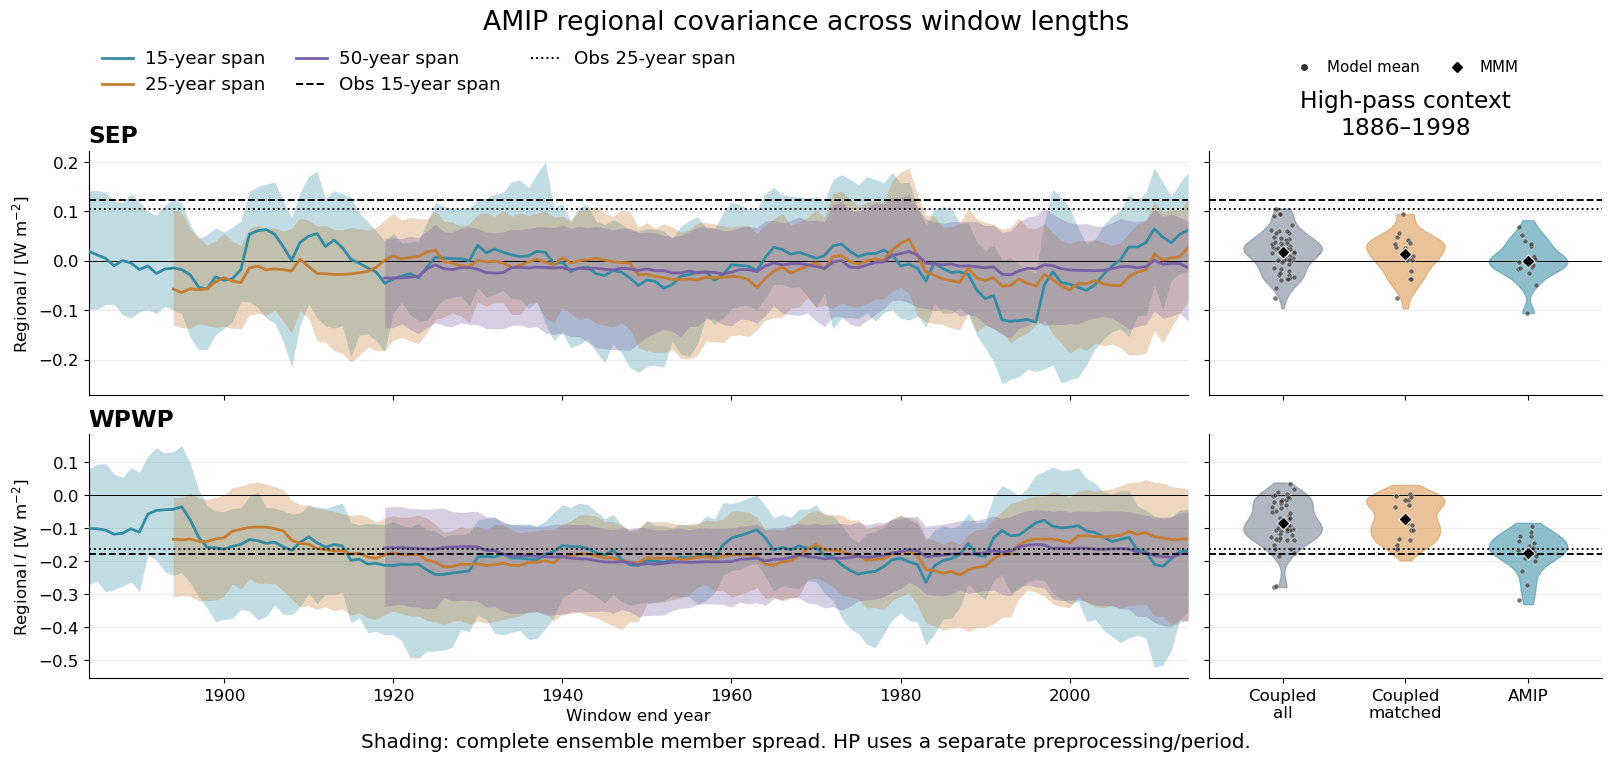

In [22]:
# %% 11. WPWP and full SEP only: the same curves, spreads, observations and HP violins
def plot_wpwp_sep_window_comparison(archive, *, figsize=(16, 7.5), savepath=None, **plot_options):
    """Reuse the existing figure styling, keeping only its first two region rows.

    The original plotting function and all earlier cells remain unchanged.
    This rearranges existing plot artists; it does not recalculate diagnostics.
    plot_options accepts the same options as plot_regional_window_comparison.
    """
    fig, original_axes, plotted = plot_regional_window_comparison(archive, figsize=figsize, **plot_options)
    xlabels = [ax.get_xlabel() for ax in original_axes[-1]]

    # WPWP and full SEP are already the first two rows. Remove the half-SEP rows
    # and give the retained axes a new two-row layout, so no empty panels remain.
    axes = original_axes[:2].copy()
    # axes = axes[::-1]
    for ax in original_axes[2:].ravel():
        ax.remove()
    grid = fig.add_gridspec(2, 2, width_ratios=[4.2, 1.5])
    for (row, column), ax in np.ndenumerate(axes):
        ax.set_subplotspec(grid[row, column])

    # Full SEP is now the bottom row: restore its tick labels and transfer the
    # existing start-/end-year label. Legends, colors and within-row y scales stay.
    for ax, label in zip(axes[-1], xlabels):
        ax.tick_params(axis="x", labelbottom=True)
        ax.set_xlabel(label)
    if savepath is not None:
        path = Path(savepath)
        path.parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(path, dpi=250, bbox_inches="tight")
    return fig, axes, {region: plotted[region] for region in ["WPWP", "SEP"]}


# Run cell 8 first so the original plotting function is available. This cell
# loads the saved comparison archive, so no model/observation calculations rerun.
wc_archive = np.load(wc_output_dir / "window_comparison.npy", allow_pickle=True).item()
wc_two_year_position = "end"              # Or "start", matching the earlier two display choices.
wc_save_two_region_figure = True
fig_wpwp_sep, axes_wpwp_sep, wc_plotted_wpwp_sep = plot_wpwp_sep_window_comparison(
    wc_archive, year_position=wc_two_year_position, ribbon_alpha=.3, show_full_range=True,
    show_hp_model_means=True, bw_adjust=1., row_ylims=None,
    savepath=wc_output_dir / f"figures/AMIP_window_lengths_with_HP_WPWP_SEP_{wc_two_year_position}_year.svg"
    if wc_save_two_region_figure else None,font_scale=1.2)
plt.show()


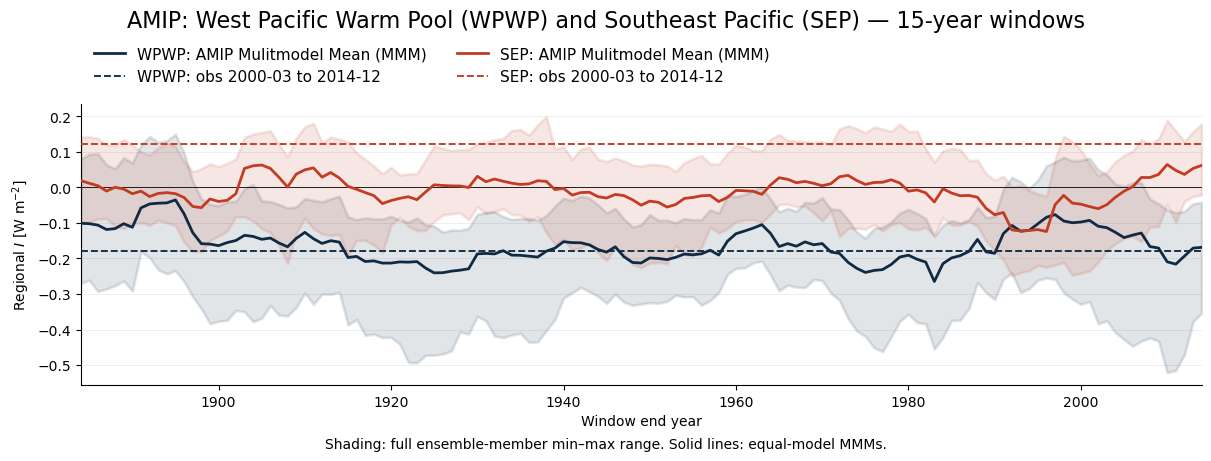

In [6]:
# %% 12. One common axis: 178-month WPWP and SEP, with full ensemble-member ranges
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.text import Text
from pathlib import Path


def plot_wpwp_sep_178(archive, *, year_position="end", obs_periods=("2000_2014", "2000_2024"),
                      figsize=(12, 4.5), ribbon_alpha=.12, font_scale=1., ylim=None, savepath=None):
    """Overlay the two AMIP regional MMM indices and full member min/max envelopes.

    Observation colors identify regions; dashed/dotted lines identify periods.
    Select only 2000_2014 in obs_periods for two references total instead of four.
    The curves and envelopes are saved diagnostics, not recalculated averages.
    """
    if year_position not in ["start", "end"]:
        raise ValueError("year_position must be 'start' or 'end'.")
    if not np.isfinite(font_scale) or font_scale <= 0:
        raise ValueError("font_scale must be positive.")
    obs_periods = list(obs_periods)
    if not obs_periods or len(set(obs_periods)) != len(obs_periods) or any(p not in ("2000_2014", "2000_2024") for p in obs_periods):
        raise ValueError("obs_periods must select 2000_2014 and/or 2000_2024, without duplicates.")

    # Use the actual coordinates saved for the 178-month windows. Their indices
    # and member ranges are identical whichever year convention is displayed.
    coordinates = archive["window_coordinates"][178]
    if year_position == "end":
        dates = np.asarray(coordinates["end_month"], dtype="datetime64[M]")
        if np.isnat(dates).any():
            raise ValueError("Missing 178-month window-end dates.")
        years = dates.astype("datetime64[Y]").astype(int) + 1970
    else:
        years = np.asarray(coordinates["start_year"])
    if years.ndim != 1 or not len(years) or not np.isfinite(years).all() or np.any(np.diff(years) <= 0):
        raise ValueError("Expected finite, increasing window years.")

    # Colors now distinguish REGIONS, not window lengths. Keep the familiar
    # solid MMM curves and light shading, with one shared physical-unit y axis.
    region_colors = {"WPWP": "#348CA4", "SEP": "#C47D32"}
    region_colors = {"WPWP": "#3B5998", "SEP": "#348CA4"}
    region_colors = {
    "WPWP": "#3B5998",  # Increased Red from 3B -> 5C (Adds a subtle, rich violet undertone)
    "SEP":  "#108CA4" # Decreased Red from 34 -> 10 (Deepens the cool, crisp teal-blue contrast)
    }
    region_colors = {
    "WPWP": "#4E8CA4",  # Shifted UP in Red (Slate Denim Blue)
    "SEP":  "#0A8CA4"   # Shifted DOWN in Red (Vibrant Ice-Teal)
    }
    region_colors = {
    "WPWP": "#C23B22",  # Shifted FURTHER UP in Red (Muted Steel Blue)
    "SEP":  "Black"   # Shifted ALL THE WAY DOWN in Red (Deep Cyan-Teal)
    }
    region_colors = {
    "WPWP": "#102A43",  # Shifted FURTHER UP in Red (Muted Steel Blue)
    "SEP":  "#C23B22"   # Shifted ALL THE WAY DOWN in Red (Deep Cyan-Teal)
    }
    
    obs_styles = {"2000_2014": "--", "2000_2024": ":"}
    fig, ax = plt.subplots(figsize=figsize, layout="constrained")
    plotted = {}
    for region, color in region_colors.items():
        spread = archive["spread"][178][region]
        mean, lower, upper = [np.asarray(spread[key]) for key in ["MMM", "minimum", "maximum"]]
        if any(values.shape != years.shape for values in [mean, lower, upper]):
            raise ValueError(f"{region}: MMM and full-range arrays must match the window years.")

        # These extrema span ALL members of ALL AMIP models at each year,
        # not the range of model means or the central-80% interval. The solid
        # curve remains the saved equal-model MMM (mean members, then models).
        ax.fill_between(years, lower, upper, color=color, alpha=ribbon_alpha, linewidth=2)
        ax.plot(years, mean, color=color, linewidth=2., zorder=4, label=f"{region}: AMIP Mulitmodel Mean (MMM)")
        plotted[region] = {"years": years, "MMM": mean, "minimum": lower, "maximum": upper, "observations": {}}

        # Same regional observations as the earlier figures. The longer observed
        # period is contextual: it is NOT another 178-month window.
        for period in obs_periods:
            value = float(archive["observations"][period][region]["I"])
            dates = archive["observation_coordinates"][period]
            ax.axhline(value, color=color, linestyle=obs_styles[period], linewidth=1.35, zorder=5,
                       label=f"{region}: obs {dates['start_month']} to {dates['end_month']}")
            plotted[region]["observations"][period] = value

    # Retain the original simple styling and text-only scaling option; no
    # redesigned tick layout, enlarged markers, or custom subplot spacing.
    ax.axhline(0., color="k", linewidth=.6, zorder=1)
    ax.set_xlim(years[0], years[-1])
    if ylim is not None:
        ax.set_ylim(ylim)
    ax.set_xlabel("Window start year (March)" if year_position == "start" else "Window end year")
    ax.set_ylabel(r"Regional $I$ [W m$^{-2}$]")
    ax.grid(axis="y", color=".92", linewidth=.6)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(loc="lower left", bbox_to_anchor=(0, 1.02), ncol=2, fontsize=11, frameon=False)
    fig.suptitle("AMIP: West Pacific Warm Pool (WPWP) and Southeast Pacific (SEP) — 15-year windows", fontsize=16)
    fig.supxlabel("Shading: full ensemble-member min–max range. Solid lines: equal-model MMMs.", fontsize=10)
    if font_scale != 1.:
        for text in fig.findobj(match=Text):
            text.set_fontsize(text.get_fontsize()*font_scale)
    if savepath is not None:
        path = Path(savepath)
        path.parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(path, dpi=300, bbox_inches="tight")
    return fig, ax, plotted


# Only the small saved archive is needed. No HP data are plotted, and none of
# the existing multi-panel figures are changed. Select one or both obs periods.
wc_archive = np.load(wc_output_dir / "window_comparison.npy", allow_pickle=True).item()
wc_common_year_position = "end"             # Or "start".
wc_common_obs_periods = ("2000_2014", )#"2000_2024")  # ("2000_2014",) gives one obs line per region.
wc_save_common_figure = True
fig_wpwp_sep_178, ax_wpwp_sep_178, wc_plotted_wpwp_sep_178 = plot_wpwp_sep_178(
    wc_archive, year_position=wc_common_year_position, obs_periods=wc_common_obs_periods,
    ribbon_alpha=.12, font_scale=1.,
    savepath=wc_output_dir / f"figures/AMIP_WPWP_SEP_n178_common_axis_{wc_common_year_position}_year.png"
    if wc_save_common_figure else None)
plt.show()


I
amip_hist
I_inside
amip_hist
I
historical_matched
I_inside
historical_matched


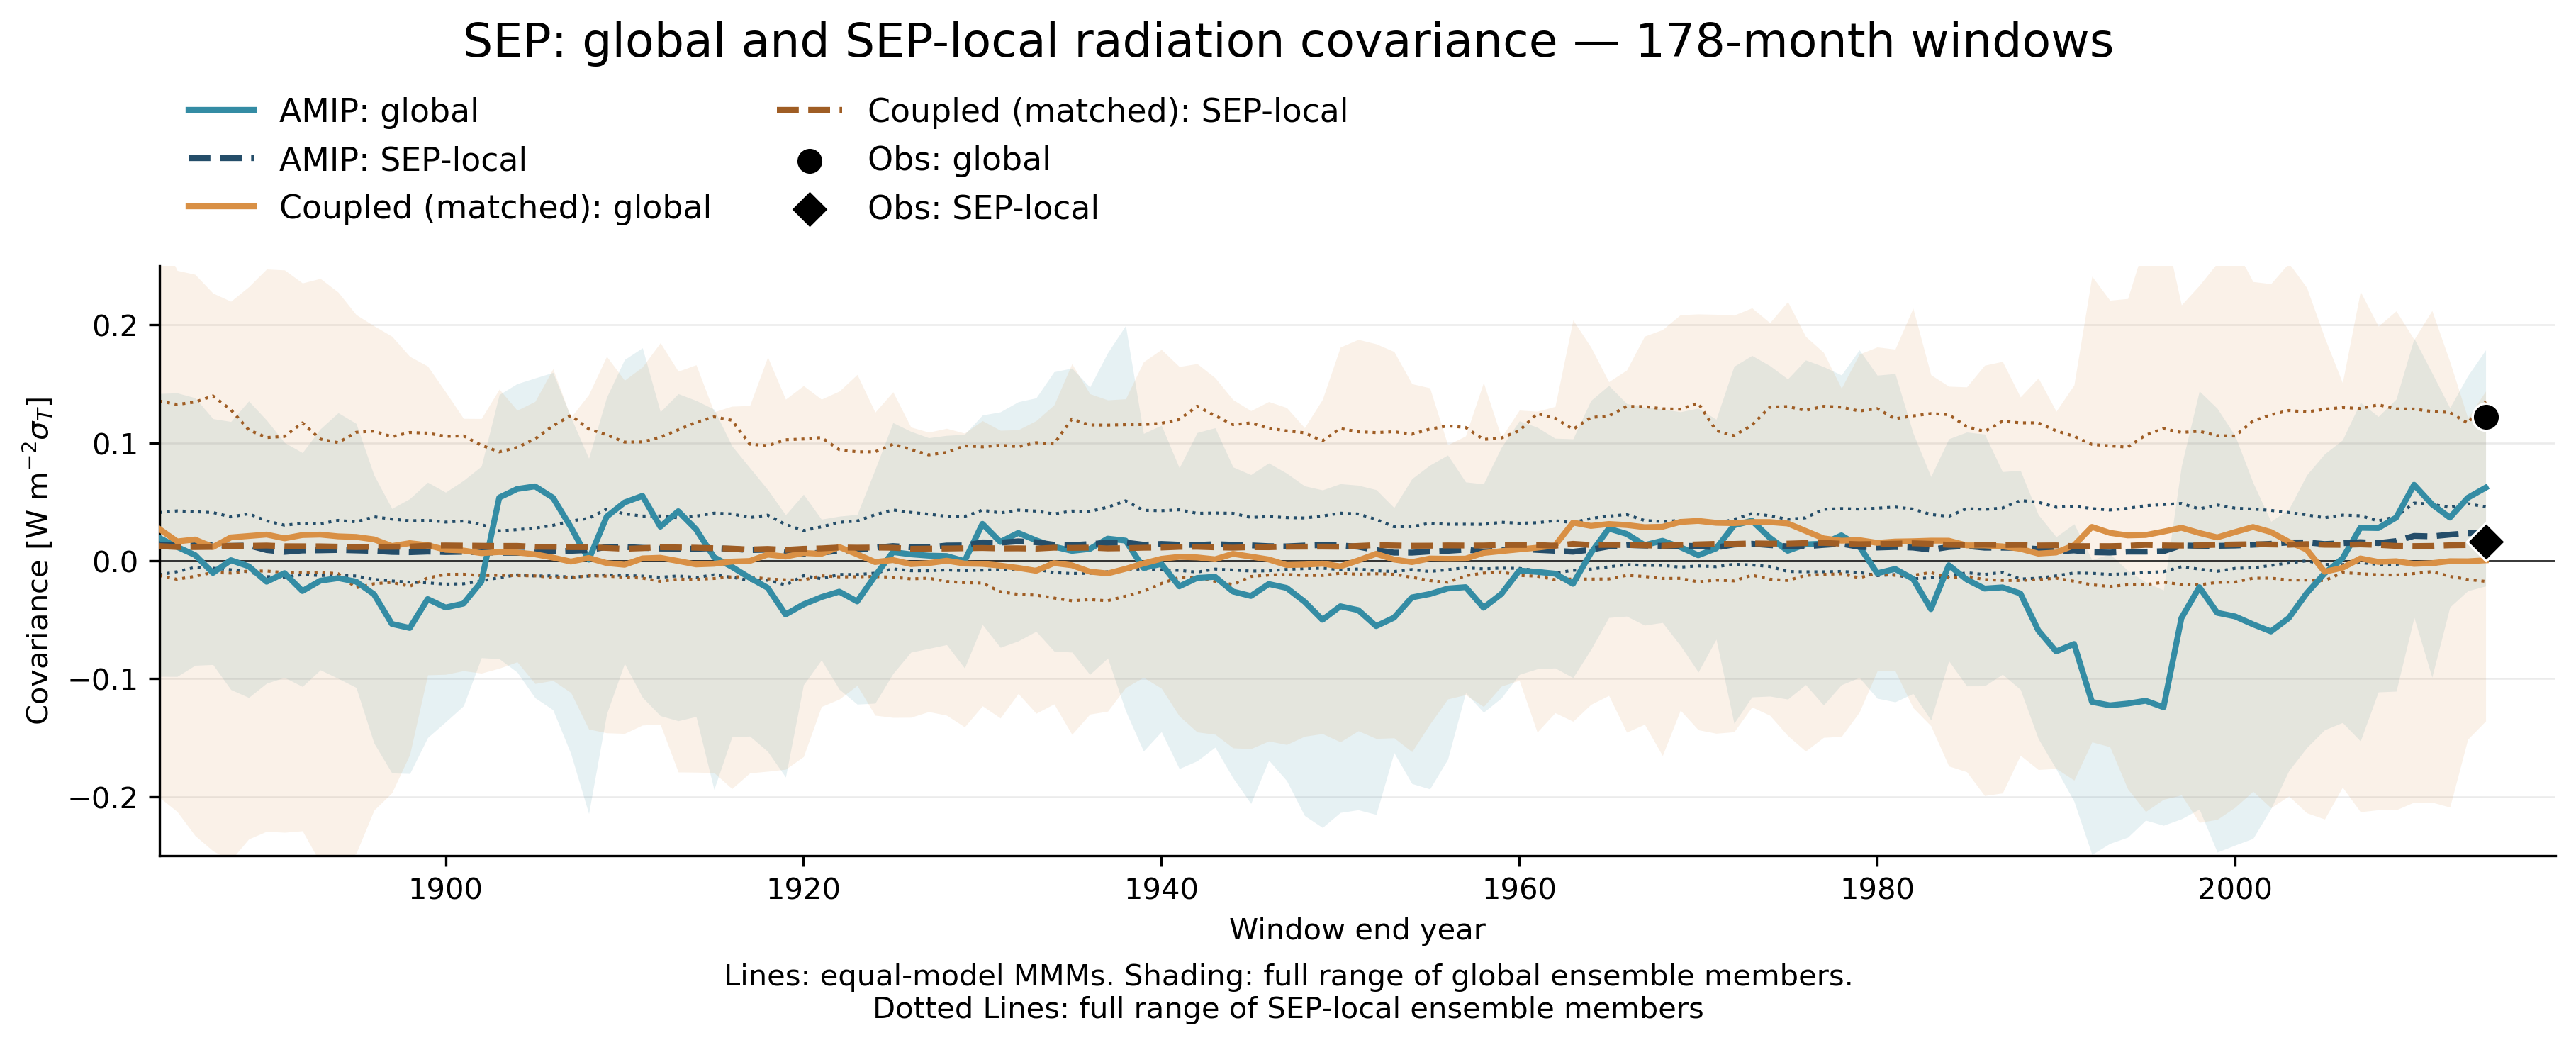

In [5]:
# %% 13. SEP only: global versus inside-SEP covariance, AMIP versus coupled
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.text import Text
from pathlib import Path


def plot_sep_global_local(archive, *, coupled_experiment="historical_matched", year_position="end",
                          figsize=(12, 4.8), ribbon_alpha=.12, font_scale=1., ylim=None, savepath=None,
                          observations=None,obs_period="2000_2014",):
    """Four MMM curves and full member ranges from the 178-month attribution archive.

    I = Cov(A_SEP, R_global); I_inside is the global-area-weighted contribution
    from radiation inside SEP. A_SEP is the SEP area mean of local standardized
    temperature, not restandardized. These are covariances, not causal slopes.
    """
    if coupled_experiment not in ["historical_matched", "historical"]:
        raise ValueError("coupled_experiment must be 'historical_matched' or 'historical'.")
    if year_position not in ["start", "end"]:
        raise ValueError("year_position must be 'start' or 'end'.")
    if not np.isfinite(font_scale) or font_scale <= 0:
        raise ValueError("font_scale must be positive.")
    experiments = ["amip_hist", coupled_experiment]
    names = {experiment: list(archive["model_names"][experiment]) for experiment in experiments}
    if any(not v or len(v) != len(set(v)) for v in names.values()):
        raise ValueError("Each experiment must have a nonempty, unique model list.")
    if coupled_experiment == "historical_matched" and set(names[coupled_experiment]) != set(names["amip_hist"]):
        raise ValueError("Matched coupled and AMIP must contain the same model set.")

    # Use the dates from the original four-region attribution archive, which
    # contains BOTH experiments and both radiation budgets for each member.
    coordinates = archive["coordinates"]
    starts, ends = [np.asarray(coordinates[key], dtype="datetime64[M]") for key in ["start_month", "end_month"]]
    if (np.isnat(starts).any() or np.isnat(ends).any() or starts.shape != ends.shape
            or np.any((ends-starts).astype(int) + 1 != 178)):
        raise ValueError("Expected complete 178-month window dates.")
    years = (ends.astype("datetime64[Y]").astype(int) + 1970 if year_position == "end"
             else np.asarray(coordinates["start_year"]))
    if years.ndim != 1 or not len(years) or not np.isfinite(years).all() or np.any(np.diff(years) <= 0):
        raise ValueError("Expected finite, increasing window years.")

    # Two hue families identify experiments; darker dashed curves are the SEP
    # radiation contribution. Each ribbon matches its own curve's color.
    colors = {"amip_hist": {"I": "#348CA4", "I_inside": "#244D69"},
              coupled_experiment: {"I": "#D99045", "I_inside": "#9F5D24"}}
    labels = {"amip_hist": "AMIP", coupled_experiment: "Coupled (matched)" if coupled_experiment == "historical_matched" else "Coupled (all)"}
    components = {"I": ("global", "-"), "I_inside": ("SEP-local", "--")}
    fig, ax = plt.subplots(figsize=figsize, layout="constrained", dpi=300)
    plotted = {}
    for experiment in experiments:
        plotted[experiment] = {}
        for quantity, (label, linestyle) in components.items():
            member_dict = archive["member_values"]["SEP"][experiment][quantity]
            arrays = [np.asarray(member_dict[model], dtype=float) for model in names[experiment]]
            if any(a.ndim != 2 or not len(a) or a.shape[1:] != years.shape or not np.isfinite(a).all() for a in arrays):
                raise ValueError(f"{experiment}/{quantity}: expected complete (member, window) arrays.")

            # Pool members ONLY for the full-range extrema. Retain the saved
            # equal-model MMM and verify its member -> model -> MMM averaging.
            members = np.concatenate(arrays, axis=0)
            lower, upper = members.min(axis=0), members.max(axis=0)
            mean = np.asarray(archive["MMM_values"]["SEP"][experiment][quantity], dtype=float)
            if mean.shape != years.shape:
                raise ValueError(f"{experiment}/{quantity}: MMM shape does not match window years.")
            np.testing.assert_allclose(mean, np.mean([a.mean(axis=0) for a in arrays], axis=0),
                                       rtol=1e-8, atol=1e-10, err_msg=f"{experiment}/{quantity}: inconsistent saved MMM")
            color = colors[experiment][quantity]
            print(quantity)
            print(experiment)
            if quantity =='I_inside':
                ax.plot(years,upper,color=color, linewidth=1,linestyle=':')
                ax.plot(years,lower,color=color, linewidth=1,linestyle=':')
                # ax.fill_between(years, lower, upper, color=color, alpha=1, linewidth=1,linestyle=':')
            else:
                ax.fill_between(years, lower, upper, color=color, alpha=ribbon_alpha, linewidth=0)
            ax.plot(years, mean, color=color, linestyle=linestyle, linewidth=2., zorder=4,
                    label=f"{labels[experiment]}: {label}")
            plotted[experiment][quantity] = {"years": years, "MMM": mean, "minimum": lower, "maximum": upper,
                                              "model_names": names[experiment], "n_models": len(arrays), "n_members": len(members)}


    # Observations are two scalar references, NOT part of the MMM or spread.
    # Place both at their actual start/end year. With the matched 2000–2014
    # period this is the final model window; a small margin keeps symbols clear.
    right_edge = years[-1]
    if observations is not None:
        obs_dates = observations["period_coordinates"][obs_period]
        obs_start, obs_end = [np.datetime64(obs_dates[key], "M") for key in ["start_month", "end_month"]]
        if np.isnat(obs_start) or np.isnat(obs_end) or obs_end < obs_start:
            raise ValueError("Expected valid observational start/end months.")
        obs_date = obs_start if year_position == "start" else obs_end
        obs_year = int(obs_date.astype("datetime64[Y]").astype(int)) + 1970
        obs_label = f"{str(obs_start)}–{str(obs_end)}"
        obs_values = observations["values"][obs_period]["SEP"]
        plotted["observations"] = {"period": obs_period, "year": obs_year}
        for quantity, marker in [("I", "o"), ("I_inside", "D")]:
            value = np.asarray(obs_values[quantity], dtype=float)
            if value.ndim != 0 or not np.isfinite(value):
                raise ValueError(f"Observed SEP {quantity} must be a finite scalar.")
            ax.scatter(obs_year, float(value), marker=marker, s=85, facecolor="black",
                       edgecolor="white", linewidth=.8, zorder=7,
                       label=f"Obs: {components[quantity][0]}")
            plotted["observations"][quantity] = float(value)
        right_edge = max(right_edge, obs_year) + .03*max(np.ptp(years), 1)

    # SEP-local is a contribution to the GLOBAL mean, not radiation averaged
    # over SEP alone: I_inside + I_outside = I. It includes within-SEP cross-cell
    # covariances, unlike the pointwise cov(Z_i, R_i) / regTiRi diagnostic.
    ax.axhline(0., color="k", linewidth=.6, zorder=1)
    # ax.set_xlim(years[0], years[-1])
    ax.set_xlim(years[0], right_edge)
    if ylim is not None:
        ax.set_ylim(ylim)
    ax.set_xlabel("Window start year (March)" if year_position == "start" else "Window end year")
    ax.set_ylabel(r"Covariance [W m$^{-2} \sigma_T$]")
    ax.grid(axis="y", color=".92", linewidth=.6)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(loc="lower left", bbox_to_anchor=(0, 1.02), ncol=2, fontsize=11, frameon=False)
    fig.suptitle("SEP: global and SEP-local radiation covariance — 178-month windows", fontsize=16)
    fig.supxlabel("Lines: equal-model MMMs. Shading: full range of global ensemble members.\n"
                  "Dotted Lines: full range of SEP-local ensemble members", fontsize=10)
    if font_scale != 1.:
        for text in fig.findobj(match=Text):
            text.set_fontsize(text.get_fontsize()*font_scale)
    if savepath is not None:
        path = Path(savepath)
        path.parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(path, dpi=250, bbox_inches="tight")
    return fig, ax, plotted


# Load the compact FOUR-REGION ATTRIBUTION series, not window_comparison.npy:
# the latter only contains AMIP total I and cannot supply this inside-SEP split.
# This cell runs independently; no raw data or earlier plot functions are needed.


sep_comparison_dir = Path("/scratch/leiff/MCA/amip_clean/data/maps_2000_2014_covImp/overlap_core_200003_201412/stationarity/four_region_attribution/run_01")
sep_comparison_archive = np.load(sep_comparison_dir / "regional_series.npy", allow_pickle=True).item()
sep_coupled_experiment = "historical_matched"  # Or "historical", if that group was calculated.

sep_obs_path = sep_comparison_dir.parents[1] / "observational_region_D/run_01/observational_D.npy"
sep_obs_archive = np.load(sep_obs_path, allow_pickle=True).item()
sep_obs_period = "2000_2014"  # Matched 178 months; "2000_2024" is longer-period context.

sep_year_position, sep_save_figure = "end", True
fig_sep_responses, ax_sep_responses, sep_response_spread = plot_sep_global_local(
    sep_comparison_archive, coupled_experiment=sep_coupled_experiment, year_position=sep_year_position,
    ribbon_alpha=.12, font_scale=1.,
    observations=sep_obs_archive, obs_period=sep_obs_period,
    savepath=sep_comparison_dir / f"figures/SEP_global_local_AMIP_{sep_coupled_experiment}_{sep_year_position}_year.png"
    if sep_save_figure else None,ylim=(-0.25,0.25))
plt.show()


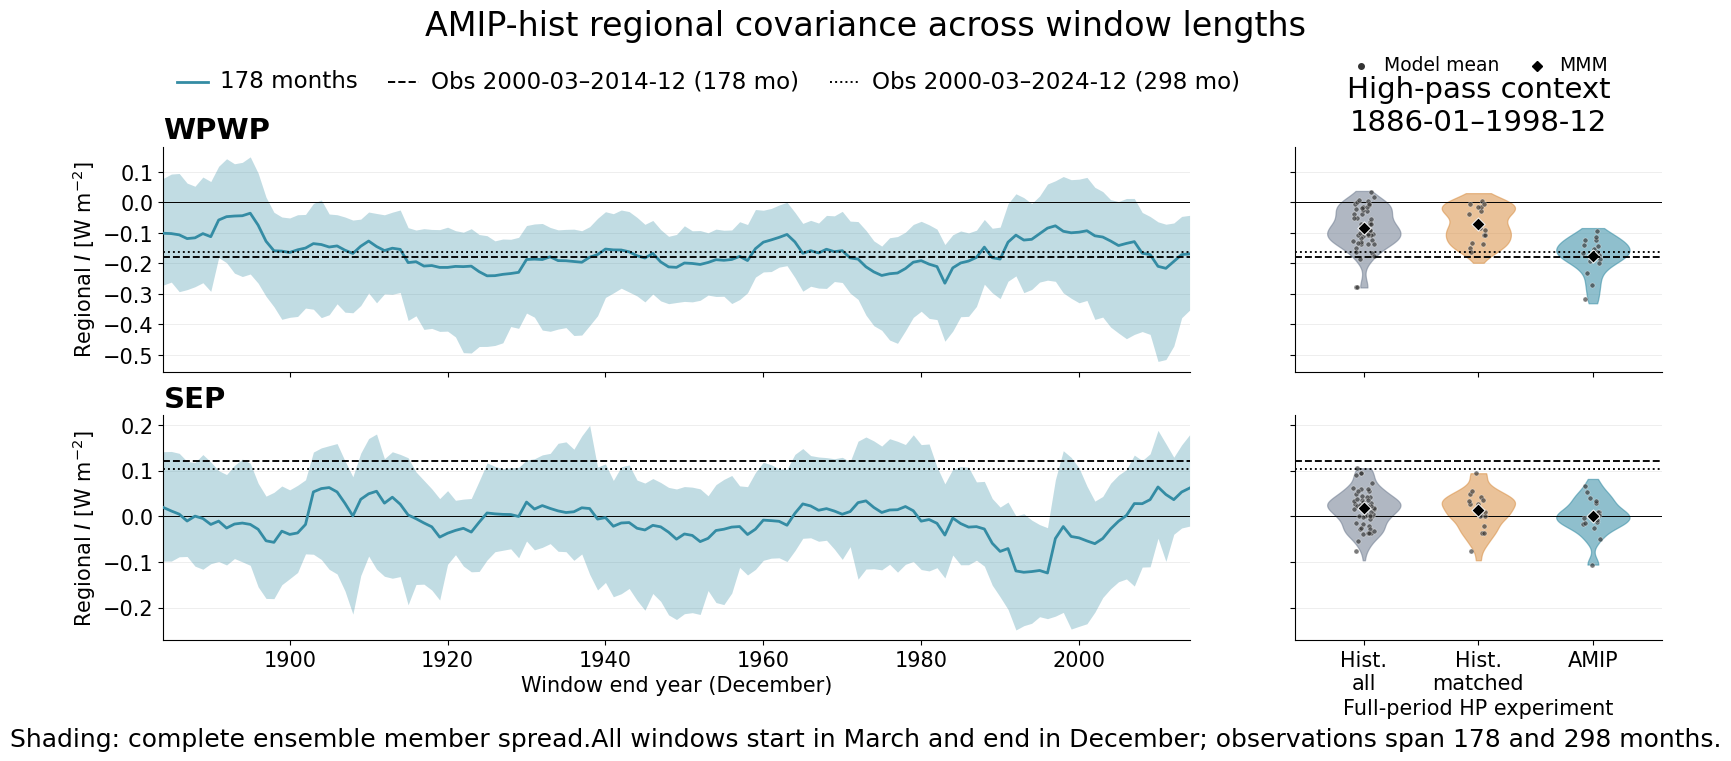

In [26]:
# %% 11. WPWP and full SEP only: the same curves, spreads, observations and HP violins
def plot_wpwp_sep_window_comparison(archive, *, figsize=(16, 7.5), savepath=None, **plot_options):
    """Reuse the existing figure styling, keeping only its first two region rows.

    The original plotting function and all earlier cells remain unchanged.
    This rearranges existing plot artists; it does not recalculate diagnostics.
    plot_options accepts the same options as plot_regional_window_comparison.
    """
    fig, original_axes, plotted = plot_regional_window_comparison(archive, figsize=figsize, **plot_options)
    xlabels = [ax.get_xlabel() for ax in original_axes[-1]]

    # WPWP and full SEP are already the first two rows. Remove the half-SEP rows
    # and give the retained axes a new two-row layout, so no empty panels remain.
    axes = original_axes[:2].copy()
    for ax in original_axes[2:].ravel():
        ax.remove()
    grid = fig.add_gridspec(2, 2, width_ratios=[4.2, 1.5])
    for (row, column), ax in np.ndenumerate(axes):
        ax.set_subplotspec(grid[row, column])

    # Full SEP is now the bottom row: restore its tick labels and transfer the
    # existing start-/end-year label. Legends, colors and within-row y scales stay.
    for ax, label in zip(axes[-1], xlabels):
        ax.tick_params(axis="x", labelbottom=True)
        ax.set_xlabel(label)
    if savepath is not None:
        path = Path(savepath)
        path.parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(path, dpi=250, bbox_inches="tight")
    return fig, axes, {region: plotted[region] for region in ["WPWP", "SEP"]}


# Run cell 8 first so the original plotting function is available. This cell
# loads the saved comparison archive, so no model/observation calculations rerun.
wc_archive = np.load(wc_output_dir / "window_comparison.npy", allow_pickle=True).item()
wc_two_year_position = "end"              # Or "start", matching the earlier two display choices.
wc_save_two_region_figure = True
fig_wpwp_sep, axes_wpwp_sep, wc_plotted_wpwp_sep = plot_wpwp_sep_window_comparison(
    wc_archive, year_position=wc_two_year_position, ribbon_alpha=.3, show_full_range=True,
    show_hp_model_means=True, bw_adjust=1., row_ylims=None,
    savepath=wc_output_dir / f"figures/AMIP_just15_with_HP_WPWP_SEP_{wc_two_year_position}_year.png"
    if wc_save_two_region_figure else None, lengths=[178],font_scale=1.5)
plt.show()


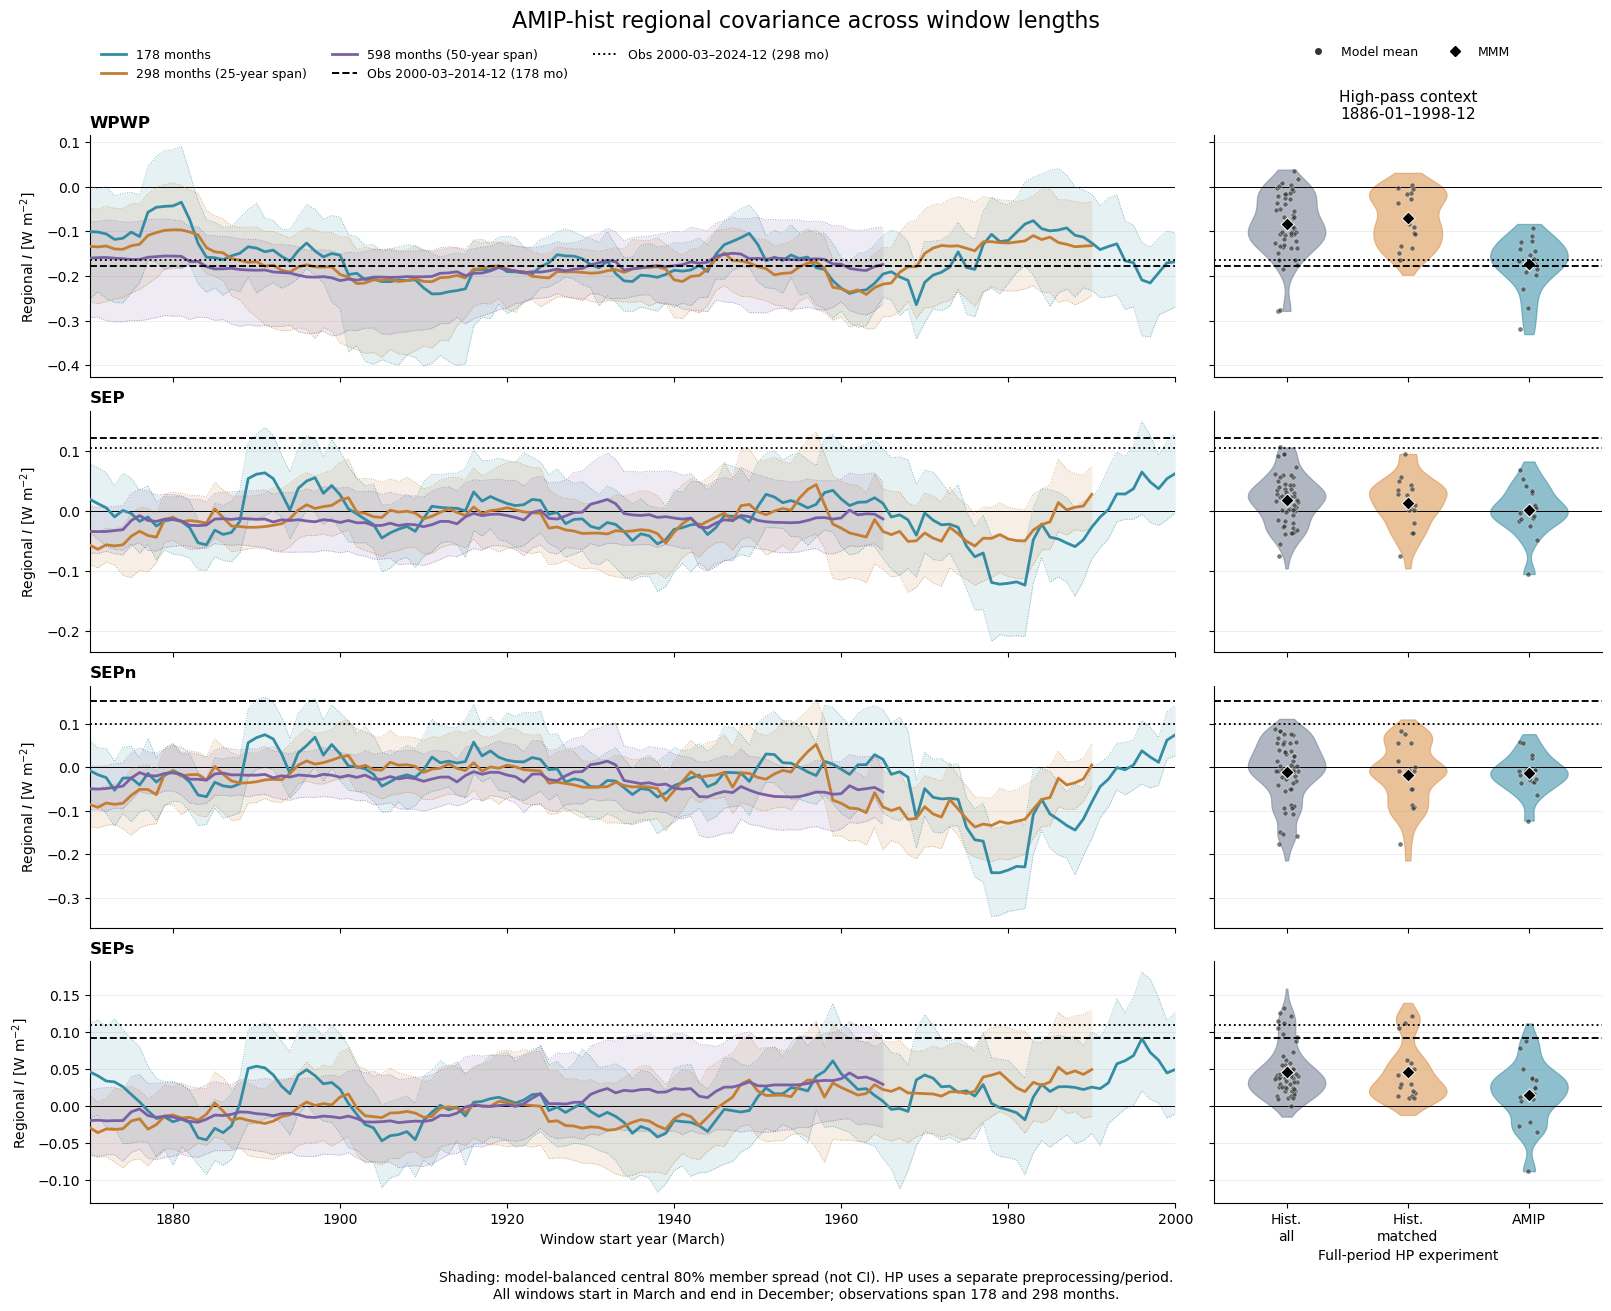

In [4]:
# %% 9. Load the small complete archive and plot; no monthly data needed here
wc_archive = np.load(wc_output_dir / "window_comparison.npy", allow_pickle=True).item()
wc_save_figure = True
fig_window_comparison, axes_window_comparison, wc_plotted = plot_regional_window_comparison(
    wc_archive, ribbon_alpha=.12, show_full_range=False, show_hp_model_means=True, bw_adjust=1., row_ylims=None,
    savepath=wc_output_dir / "figures/AMIP_window_lengths_with_HP.png" if wc_save_figure else None)
plt.show()


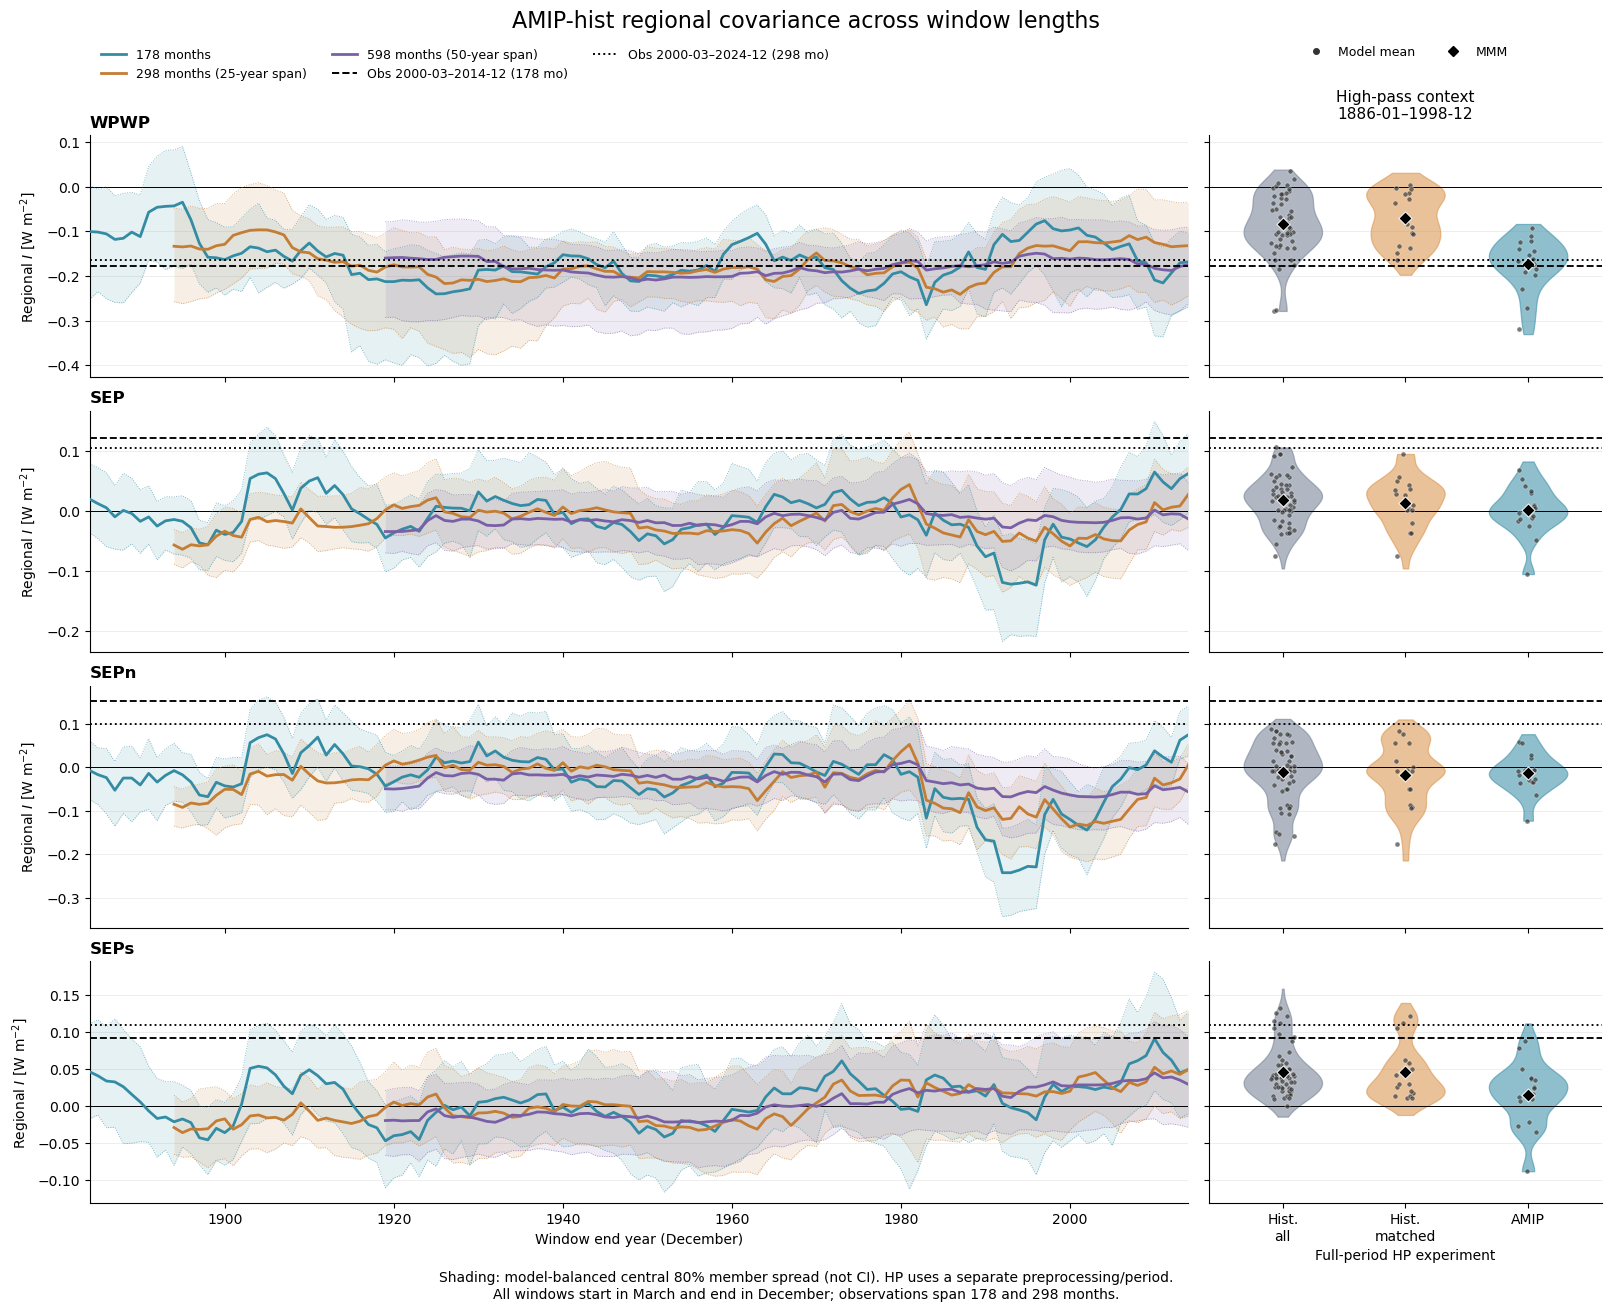

In [23]:
# %% 10. Alternative display: the SAME diagnostics plotted by window END year
# Run cell 8 again after updating the function, then run this cell. No raw data
# or recalculation are needed. Longer windows now begin later on the x axis;
# all three series end at December 2014. The start-year figure is not overwritten.
wc_archive = np.load(wc_output_dir / "window_comparison.npy", allow_pickle=True).item()
wc_save_end_year_figure = True
fig_window_comparison_end, axes_window_comparison_end, wc_plotted_end = plot_regional_window_comparison(
    wc_archive, year_position="end", ribbon_alpha=.12, show_full_range=False,
    show_hp_model_means=True, bw_adjust=1., row_ylims=None,
    savepath=wc_output_dir / "figures/AMIP_window_lengths_with_HP_end_year.png" if wc_save_end_year_figure else None)
plt.show()


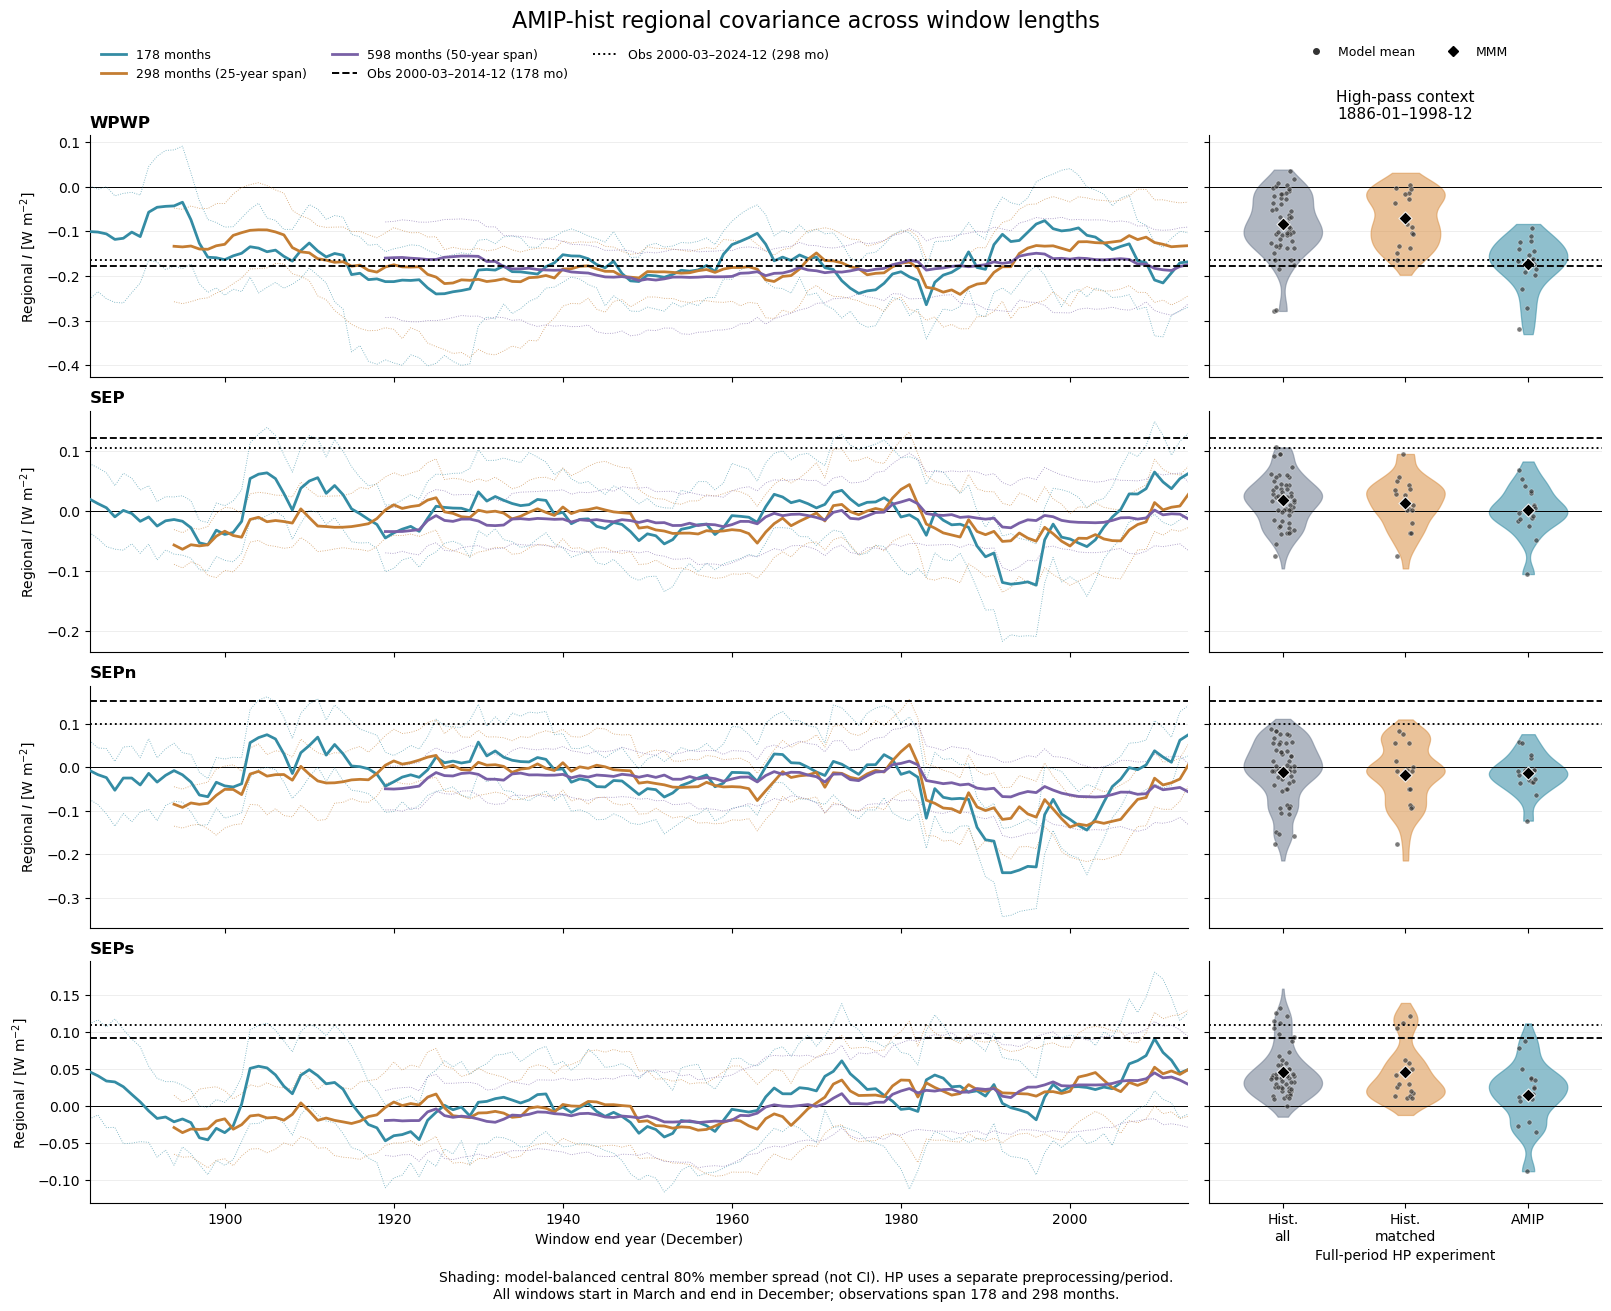

In [24]:
# %% 10. Alternative display: the SAME diagnostics plotted by window END year
# Run cell 8 again after updating the function, then run this cell. No raw data
# or recalculation are needed. Longer windows now begin later on the x axis;
# all three series end at December 2014. The start-year figure is not overwritten.
wc_archive = np.load(wc_output_dir / "window_comparison.npy", allow_pickle=True).item()
wc_save_end_year_figure = True
fig_window_comparison_end, axes_window_comparison_end, wc_plotted_end = plot_regional_window_comparison(
    wc_archive, year_position="end", ribbon_alpha=0, show_full_range=False,
    show_hp_model_means=True, bw_adjust=1., row_ylims=None,
    savepath=wc_output_dir / "figures/AMIP_window_lengths_with_HP_end_year_noRange.png" if wc_save_end_year_figure else None)
plt.show()


In [24]:
wc_output_dir

PosixPath('/scratch/leiff/MCA/amip_clean/data/maps_2000_2014_covImp/overlap_core_200003_201412/stationarity/window_length_comparison/run_01')

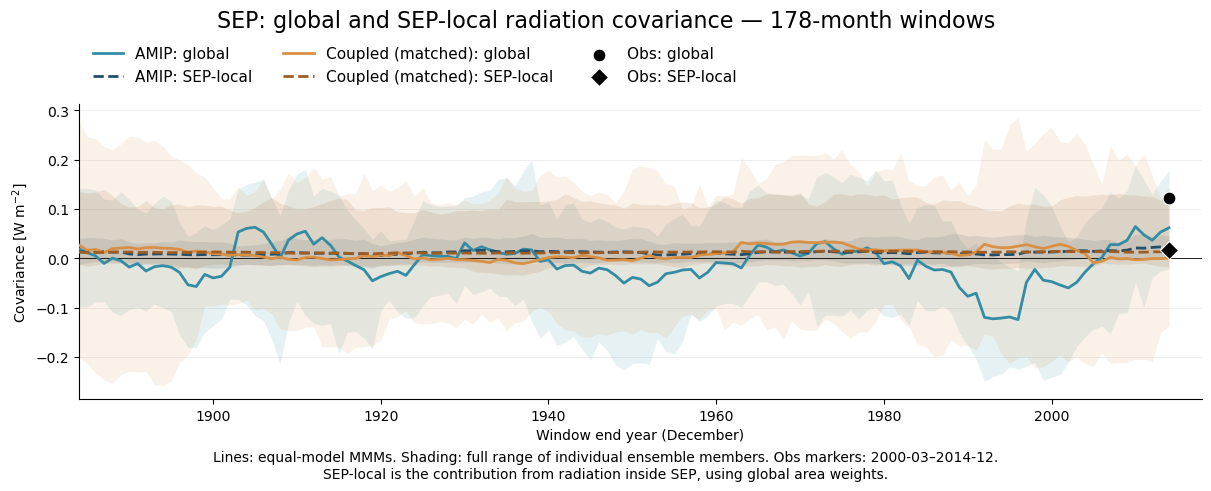

In [1]:
# %% 13. SEP only: global versus inside-SEP covariance, AMIP versus coupled
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.text import Text
from pathlib import Path


def plot_sep_global_local(archive, *, coupled_experiment="historical_matched", year_position="end",
                          observations=None, obs_period="2000_2014",
                          figsize=(12, 4.8), ribbon_alpha=.12, font_scale=1., ylim=None, savepath=None):
    """Four MMM curves and full member ranges from the 178-month attribution archive.

    I = Cov(A_SEP, R_global); I_inside is the global-area-weighted contribution
    from radiation inside SEP. A_SEP is the SEP area mean of local standardized
    temperature, not restandardized. These are covariances, not causal slopes.
    Optional observations come from observational_D.npy, using the same budgets.
    """
    if coupled_experiment not in ["historical_matched", "historical"]:
        raise ValueError("coupled_experiment must be 'historical_matched' or 'historical'.")
    if year_position not in ["start", "end"]:
        raise ValueError("year_position must be 'start' or 'end'.")
    if not np.isfinite(font_scale) or font_scale <= 0:
        raise ValueError("font_scale must be positive.")
    experiments = ["amip_hist", coupled_experiment]
    names = {experiment: list(archive["model_names"][experiment]) for experiment in experiments}
    if any(not v or len(v) != len(set(v)) for v in names.values()):
        raise ValueError("Each experiment must have a nonempty, unique model list.")
    if coupled_experiment == "historical_matched" and set(names[coupled_experiment]) != set(names["amip_hist"]):
        raise ValueError("Matched coupled and AMIP must contain the same model set.")

    # Use the dates from the original four-region attribution archive, which
    # contains BOTH experiments and both radiation budgets for each member.
    coordinates = archive["coordinates"]
    starts, ends = [np.asarray(coordinates[key], dtype="datetime64[M]") for key in ["start_month", "end_month"]]
    if (np.isnat(starts).any() or np.isnat(ends).any() or starts.shape != ends.shape
            or np.any((ends-starts).astype(int) + 1 != 178)):
        raise ValueError("Expected complete 178-month window dates.")
    years = (ends.astype("datetime64[Y]").astype(int) + 1970 if year_position == "end"
             else np.asarray(coordinates["start_year"]))
    if years.ndim != 1 or not len(years) or not np.isfinite(years).all() or np.any(np.diff(years) <= 0):
        raise ValueError("Expected finite, increasing window years.")

    # Two hue families identify experiments; darker dashed curves are the SEP
    # radiation contribution. Each ribbon matches its own curve's color.
    colors = {"amip_hist": {"I": "#348CA4", "I_inside": "#244D69"},
              coupled_experiment: {"I": "#D99045", "I_inside": "#9F5D24"}}
    labels = {"amip_hist": "AMIP", coupled_experiment: "Coupled (matched)" if coupled_experiment == "historical_matched" else "Coupled (all)"}
    components = {"I": ("global", "-"), "I_inside": ("SEP-local", "--")}
    fig, ax = plt.subplots(figsize=figsize, layout="constrained")
    plotted = {}
    for experiment in experiments:
        plotted[experiment] = {}
        for quantity, (label, linestyle) in components.items():
            member_dict = archive["member_values"]["SEP"][experiment][quantity]
            arrays = [np.asarray(member_dict[model], dtype=float) for model in names[experiment]]
            if any(a.ndim != 2 or not len(a) or a.shape[1:] != years.shape or not np.isfinite(a).all() for a in arrays):
                raise ValueError(f"{experiment}/{quantity}: expected complete (member, window) arrays.")

            # Pool members ONLY for the full-range extrema. Retain the saved
            # equal-model MMM and verify its member -> model -> MMM averaging.
            members = np.concatenate(arrays, axis=0)
            lower, upper = members.min(axis=0), members.max(axis=0)
            mean = np.asarray(archive["MMM_values"]["SEP"][experiment][quantity], dtype=float)
            if mean.shape != years.shape:
                raise ValueError(f"{experiment}/{quantity}: MMM shape does not match window years.")
            np.testing.assert_allclose(mean, np.mean([a.mean(axis=0) for a in arrays], axis=0),
                                       rtol=1e-8, atol=1e-10, err_msg=f"{experiment}/{quantity}: inconsistent saved MMM")
            color = colors[experiment][quantity]
            ax.fill_between(years, lower, upper, color=color, alpha=ribbon_alpha, linewidth=0)
            ax.plot(years, mean, color=color, linestyle=linestyle, linewidth=2., zorder=4,
                    label=f"{labels[experiment]}: {label}")
            plotted[experiment][quantity] = {"years": years, "MMM": mean, "minimum": lower, "maximum": upper,
                                              "model_names": names[experiment], "n_models": len(arrays), "n_members": len(members)}

    # Observations are two scalar references, NOT part of the MMM or spread.
    # Place both at their actual start/end year. With the matched 2000–2014
    # period this is the final model window; a small margin keeps symbols clear.
    right_edge = years[-1]
    if observations is not None:
        obs_dates = observations["period_coordinates"][obs_period]
        obs_start, obs_end = [np.datetime64(obs_dates[key], "M") for key in ["start_month", "end_month"]]
        if np.isnat(obs_start) or np.isnat(obs_end) or obs_end < obs_start:
            raise ValueError("Expected valid observational start/end months.")
        obs_date = obs_start if year_position == "start" else obs_end
        obs_year = int(obs_date.astype("datetime64[Y]").astype(int)) + 1970
        obs_label = f"{str(obs_start)}–{str(obs_end)}"
        obs_values = observations["values"][obs_period]["SEP"]
        plotted["observations"] = {"period": obs_period, "year": obs_year}
        for quantity, marker in [("I", "o"), ("I_inside", "D")]:
            value = np.asarray(obs_values[quantity], dtype=float)
            if value.ndim != 0 or not np.isfinite(value):
                raise ValueError(f"Observed SEP {quantity} must be a finite scalar.")
            ax.scatter(obs_year, float(value), marker=marker, s=85, facecolor="black",
                       edgecolor="white", linewidth=.8, zorder=7,
                       label=f"Obs: {components[quantity][0]}")
            plotted["observations"][quantity] = float(value)
        right_edge = max(right_edge, obs_year) + .03*max(np.ptp(years), 1)

    # SEP-local is a contribution to the GLOBAL mean, not radiation averaged
    # over SEP alone: I_inside + I_outside = I. It includes within-SEP cross-cell
    # covariances, unlike the pointwise cov(Z_i, R_i) / regTiRi diagnostic.
    ax.axhline(0., color="k", linewidth=.6, zorder=1)
    ax.set_xlim(years[0], right_edge)
    if ylim is not None:
        ax.set_ylim(ylim)
    ax.set_xlabel("Window start year (March)" if year_position == "start" else "Window end year (December)")
    ax.set_ylabel(r"Covariance [W m$^{-2}$]")
    ax.grid(axis="y", color=".92", linewidth=.6)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(loc="lower left", bbox_to_anchor=(0, 1.02), ncol=2 if observations is None else 3, fontsize=11, frameon=False)
    fig.suptitle("SEP: global and SEP-local radiation covariance — 178-month windows", fontsize=16)
    obs_note = "" if observations is None else f" Obs markers: {obs_label}."
    fig.supxlabel("Lines: equal-model MMMs. Shading: full range of individual ensemble members." + obs_note + "\n"
                  "SEP-local is the contribution from radiation inside SEP, using global area weights.", fontsize=10)
    if font_scale != 1.:
        for text in fig.findobj(match=Text):
            text.set_fontsize(text.get_fontsize()*font_scale)
    if savepath is not None:
        path = Path(savepath)
        path.parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(path, dpi=250, bbox_inches="tight")
    return fig, ax, plotted


# Load the compact FOUR-REGION ATTRIBUTION series, not window_comparison.npy:
# the latter only contains AMIP total I and cannot supply this inside-SEP split.
# This cell runs independently; no raw data or earlier plot functions are needed.
sep_comparison_dir = Path("/scratch/leiff/MCA/amip_clean/data/maps_2000_2014_covImp/overlap_core_200003_201412/stationarity/four_region_attribution/run_01")
sep_comparison_archive = np.load(sep_comparison_dir / "regional_series.npy", allow_pickle=True).item()
# This separate observational archive saves BOTH global I and I_inside.
# The window-comparison observational scalars alone do not include I_inside.
sep_obs_path = sep_comparison_dir.parents[1] / "observational_region_D/run_01/observational_D.npy"
sep_obs_archive = np.load(sep_obs_path, allow_pickle=True).item()
sep_obs_period = "2000_2014"  # Matched 178 months; "2000_2024" is longer-period context.
sep_coupled_experiment = "historical_matched"  # Or "historical", if that group was calculated.
sep_year_position, sep_save_figure = "end", True
fig_sep_responses, ax_sep_responses, sep_response_spread = plot_sep_global_local(
    sep_comparison_archive, coupled_experiment=sep_coupled_experiment, year_position=sep_year_position,
    observations=sep_obs_archive, obs_period=sep_obs_period,
    ribbon_alpha=.12, font_scale=1.,
    savepath=sep_comparison_dir / f"figures/SEP_global_local_AMIP_{sep_coupled_experiment}_{sep_year_position}_year_obs_{sep_obs_period}.png"
    if sep_save_figure else None)
plt.show()
